In [1]:
%pip install numpy scipy pandas rdata matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
"""
xol_tables.py  -  complete code, from downloading the data to the result tables
===============================================================================

Paper: "How Precisely Can an Excess-of-Loss Layer Be Priced?
        A Precision Rule for Peaks-over-Threshold Premiums" (NAAJ revision)

This single file is all you need. It does not import or call any other code file.
It uses only numpy, pandas and rdata (plus Python's standard library). It does NOT
use scipy, matplotlib, background processes or parallel threads, which are the usual
causes of crashes in Anaconda on Windows laptops.

Built to run safely on an ordinary laptop (for example a Dell with 8 GB of memory):
  * one maths thread only, and the memory use stays below about 0.5 GB;
  * every table is SAVED AS IT GOES (checkpoints). If the run stops for any reason
    (crash, closed window, sleep, power), simply start it again: it continues where it
    stopped and gives exactly the same numbers as an uninterrupted run;
  * if Python itself crashes, the reason is written to xol_out/crash_report.txt.

-------------------------------------------------------------------------------
HOW TO RUN  (save this file as xol_tables.py in a folder, e.g. C:\\Users\\admin)
-------------------------------------------------------------------------------
Packages (once):   pip install numpy pandas rdata

BEST - run outside Jupyter, in the "Anaconda Prompt" (Start menu -> Anaconda Prompt):
    cd C:\\Users\\admin
    python xol_tables.py              quick test of everything (about 2-3 minutes)
    python xol_tables.py --paper      the paper's settings (about 45-60 minutes)
    python xol_tables.py --paper --only table18      one table only
    python xol_tables.py --paper --fresh             ignore saved progress, start over

In a Jupyter notebook (the code runs in its own process, so the notebook cannot die):
    !python xol_tables.py
    !python xol_tables.py --paper

Or inside the notebook itself:
    import xol_tables as xt
    xt.run(quick=True)                # quick test
    xt.run(quick=False)               # paper settings
    xt.run(quick=False, only=['table12'])

Tables (steps): table2, table3, table10, table12, table9 (also gives Table 4), table18

Outputs, in the same folder as this file:
    xol_data/                 the 12 downloaded data files
    xol_out/*.csv             every result table
    xol_out/all_tables.txt    all tables in one readable text file
    xol_out/run_log.txt       everything printed on screen
    xol_out/checkpoints/      saved progress (delete it, or use --fresh, to start over)
    xol_out/crash_report.txt  only written if Python itself crashes
-------------------------------------------------------------------------------
"""

# =============================================================================
# 0. SAFE ENVIRONMENT - these lines must come BEFORE numpy is imported
# =============================================================================
import os

for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[_v] = '1'                       # one thread: less memory, no thread crashes
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'    # avoids "OMP: Error #15" in Anaconda on Windows

import sys
import gc
import math
import time
import pickle
import platform
import statistics
import faulthandler
import traceback
import urllib.request
import warnings

import numpy as np
import pandas as pd

try:
    import rdata                               # pure-Python reader for R data files
except ImportError:
    sys.exit("The package 'rdata' is missing. Install it with:  pip install rdata")

warnings.filterwarnings('ignore', message='Missing constructor for R class')

# =============================================================================
# 1. SETTINGS
# =============================================================================
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:                              # code pasted into a notebook cell
    HERE = os.getcwd()

DATA_DIR = os.path.join(HERE, 'xol_data')
OUT_DIR = os.path.join(HERE, 'xol_out')
CK_DIR = os.path.join(OUT_DIR, 'checkpoints')
LOG_FILE = os.path.join(OUT_DIR, 'run_log.txt')
CRASH_FILE = os.path.join(OUT_DIR, 'crash_report.txt')

# Replication counts: the paper's settings, and a quick test.
PAPER = dict(reps_bc=5000, reps_sub=1000, reps_boot=1000, B_boot=999)
QUICK = dict(reps_bc=300, reps_sub=100, reps_boot=30, B_boot=199)

# Random seeds used in the paper (with --paper the tables match the manuscript).
SEED_BC, SEED_SUB, SEED_BOOT_300, SEED_BOOT_1000 = 777, 4242, 20261122, 20261121

# Memory control: GPD fits are done in batches with at most this many
# (samples x exceedances). Lower it (e.g. 5_000) if memory is very tight.
# The results do not depend on this number.
GPD_FIT_BATCH = 20_000

# Simulated samples are generated in chunks of this many rows (results unchanged).
SIM_CHUNK = 250

# How often (in replications) the bootstrap study saves its progress.
BOOT_SAVE_EVERY = 20

# The 12 public data files (ReIns, fitdistrplus and CASdatasets on GitHub).
_RAW = 'https://raw.githubusercontent.com/'
FILES = {
    'secura.RData': _RAW + 'TReynkens/ReIns/master/data/secura.RData',
    'norwegianfire.RData': _RAW + 'TReynkens/ReIns/master/data/norwegianfire.RData',
    'danishuni.rda': _RAW + 'lbbe-software/fitdistrplus/master/data/danishuni.rda',
}
for _name in ('freMTPL2sev', 'freMTPLsev', 'fremarine', 'usautoBI', 'frecomfire', 'frebiloss',
              'lossalae', 'lossalaefull', 'ausautoBI8999'):
    FILES[_name + '.rda'] = _RAW + 'dutangc/CASdatasets/master/data/%s.rda' % _name

# Layers priced in the paper: dataset -> (retention R, limit L).
BENCH = {'Secura': (2e6, 3e6), 'Danish': (10., 40.), 'Norwegian 1988': (5000., 10000.)}
EXTRA = {'freMTPL2sev': (16500, 33000), 'freMTPLsev': (16100, 32200), 'fremarine': (385, 770),
         'usautoBI': (67.8, 135.6), 'frecomfire': (92.3e6, 184.6e6), 'frebiloss': (10.9e6, 21.8e6),
         'ausautoBI8999': (394000, 788000)}

# GPD threshold quantile for Table 10 (mid-grid for the benchmarks, 0.76 otherwise).
THRESHOLD_Q = {'Secura': 0.40, 'Danish': 0.88, 'Norwegian 1988': 0.80}

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)


# =============================================================================
# 2. SMALL HELPERS: printing, logging, saving, checkpoints
# =============================================================================
_CRASH_HANDLE = None


def _prepare_folders():
    """Create the output folders and switch on the crash recorder."""
    global _CRASH_HANDLE
    for folder in (DATA_DIR, OUT_DIR, CK_DIR):
        os.makedirs(folder, exist_ok=True)
    if _CRASH_HANDLE is None:
        try:
            _CRASH_HANDLE = open(CRASH_FILE, 'a')
            faulthandler.enable(file=_CRASH_HANDLE)   # records hard crashes of Python
        except Exception:
            pass


def say(text=''):
    """Print a line immediately and add it to run_log.txt."""
    print(text, flush=True)
    try:
        with open(LOG_FILE, 'a', encoding='utf8') as f:
            f.write(str(text) + '\n')
    except OSError:
        pass


def show(df, title, csv_name, digits=4):
    """Print a table, save it as CSV and append it to all_tables.txt."""
    text = df.round(digits).to_string(index=False)
    say('\n' + title)
    say(text)
    df.to_csv(os.path.join(OUT_DIR, csv_name), index=False)
    with open(os.path.join(OUT_DIR, 'all_tables.txt'), 'a', encoding='utf8') as f:
        f.write('\n%s\n%s\n' % (title, text))


class Checkpoint:
    """Saved progress of one table. Everything (including the state of the random
    number generator) is written to disk, so an interrupted run continues exactly
    where it stopped and gives the same numbers."""

    def __init__(self, name, quick, fresh=False):
        self.path = os.path.join(CK_DIR, '%s_%s.pkl' % (name, 'quick' if quick else 'paper'))
        self.data = {}
        if fresh and os.path.exists(self.path):
            os.remove(self.path)
        if os.path.exists(self.path):
            try:
                with open(self.path, 'rb') as f:
                    self.data = pickle.load(f)
                say('  (continuing from saved progress: %s)' % os.path.basename(self.path))
            except Exception:
                self.data = {}                 # damaged file: start this table again

    def get(self, key, default=None):
        return self.data.get(key, default)

    def put(self, key, value):
        self.data[key] = value

    def save(self):
        tmp = self.path + '.tmp'
        with open(tmp, 'wb') as f:
            pickle.dump(self.data, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self.path)             # atomic: never leaves half a file


def _rng_from(state_or_seed):
    """A random generator from a seed, or restored from a saved state."""
    rng = np.random.default_rng(0)
    if isinstance(state_or_seed, dict):
        rng.bit_generator.state = state_or_seed
    else:
        rng = np.random.default_rng(state_or_seed)
    return rng


# =============================================================================
# 3. DATA: download and load
# =============================================================================
def download_data():
    """Download any data file that is not yet in xol_data (about 30 MB in total)."""
    _prepare_folders()
    for fname, url in FILES.items():
        path = os.path.join(DATA_DIR, fname)
        if os.path.exists(path) and os.path.getsize(path) > 0:
            continue
        say('  downloading %s' % fname)
        try:
            urllib.request.urlretrieve(url, path + '.part')
            os.replace(path + '.part', path)
        except Exception as e:
            raise RuntimeError('Could not download %s (%s).\nDownload it by hand from\n  %s\n'
                               'and put it in %s' % (fname, e, url, DATA_DIR))
    say('  data folder: %s (all %d files present)' % (DATA_DIR, len(FILES)))


def read_r(fname):
    """Read the data frame stored in an .rda / .RData file."""
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        download_data()
    return list(rdata.read_rda(path).values())[0]


def load(name):
    """Strictly positive claim amounts of a dataset, as a numpy array."""
    if name == 'Secura':
        x = read_r('secura.RData')['size'].to_numpy(float)
    elif name == 'Danish':
        x = read_r('danishuni.rda')['Loss'].to_numpy(float)
    elif name == 'Norwegian 1988':
        d = read_r('norwegianfire.RData')
        x = d.loc[d['year'] == 88, 'size'].to_numpy(float)
    else:
        col = {'freMTPL2sev': 'ClaimAmount', 'freMTPLsev': 'ClaimAmount', 'fremarine': 'ClaimPaid',
               'usautoBI': 'LOSS', 'frecomfire': 'ClaimCost', 'frebiloss': 'ClaimCost',
               'lossalae': 'Loss', 'ausautoBI8999': 'AggClaim'}[name]
        x = read_r(name + '.rda')[col].to_numpy(float)
    x = x[np.isfinite(x)]
    return x[x > 0]


# =============================================================================
# 4. CORE FORMULAS: layer premium, derivatives, V, kappa, GPD fit, burning cost
# =============================================================================
GL_X, GL_W = np.polynomial.legendre.leggauss(128)   # Gauss-Legendre nodes, layer integral


def _nodes(a, L):
    return a + (GL_X + 1.0) * L / 2.0, GL_W * L / 2.0


def _f(xi, s):
    """GPD survival (1 + xi s)^(-1/xi); exp(-s) when xi = 0; 0 beyond the endpoint (xi < 0)."""
    if abs(xi) < 1e-8:
        return np.exp(-s)
    z = 1.0 + xi * s
    with np.errstate(invalid='ignore', divide='ignore', over='ignore'):
        out = np.exp(-np.log(np.where(z > 0, z, 1.0)) / xi)
    return np.where(z > 0, out, 0.0)


def premium(p, xi, beta, a, L):
    """Equation (1): Pi = p * int_a^{a+L} (1 + xi t / beta)^(-1/xi) dt, with p the
    exceedance proportion, a = R - u and L the layer limit."""
    t, w = _nodes(a, L)
    return p * np.sum(w * _f(xi, t / beta))


def h_terms(xi, beta, a, L):
    """Appendix B: h_xi = d log Pi / d xi and h_beta = d log Pi / d log beta."""
    t, w = _nodes(a, L)
    s = t / beta
    f = _f(xi, s)
    I0 = np.sum(w * f)
    pos = 1.0 + xi * s > 0
    wv = np.where(pos, 1.0 + xi * s, 1.0)
    if abs(xi) < 1e-6:
        dxi = f * s ** 2 / 2.0
    else:
        dxi = f * (np.log(wv) / xi ** 2 - s / (xi * wv))
    dlb = f / wv * s
    return np.sum(w * dxi) / I0, np.sum(w * dlb) / I0


def V_term(p, xi, beta, a, L, poisson=False):
    """Equation (2): V = (1 - p) + (1+xi)[(1+xi) h_xi^2 - 2 h_xi h_beta + 2 h_beta^2].
    With poisson=True the count term is 1 (Corollary 2, Poisson claim counts)."""
    hx, hb = h_terms(xi, beta, a, L)
    count = 1.0 if poisson else (1.0 - p)
    return count + (1.0 + xi) * ((1.0 + xi) * hx ** 2 - 2.0 * hx * hb + 2.0 * hb ** 2)


def kappa(p, xi, beta, a, L, poisson=False):
    """Equation (3): relative SE = kappa / sqrt(n_R)."""
    return np.sqrt(V_term(p, xi, beta, a, L, poisson) * _f(xi, a / beta))


def rel_se(nu, p, xi, beta, a, L):
    """First-order relative standard error of the premium, sqrt(V / n_u)."""
    return np.sqrt(V_term(p, xi, beta, a, L) / nu)


def lomax_q(q, xi):
    return ((1.0 - q) ** (-xi) - 1.0) / xi


def lomax_setup(xi, qu, qR, LR):
    """GPD parameters above the threshold for a Lomax tail (threshold quantile qu,
    retention quantile qR, limit L = LR * R)."""
    u, R = lomax_q(qu, xi), lomax_q(qR, xi)
    return dict(p=1.0 - qu, xi=xi, beta=1.0 + xi * u, a=R - u, L=LR * R, u=u, R=R)


def lomax_kappa(xi, qu, qR, LR, poisson=False):
    s = lomax_setup(xi, qu, qR, LR)
    return kappa(s['p'], s['xi'], s['beta'], s['a'], s['L'], poisson)


def _profile(theta, Y):
    """GPD profile log-likelihood per observation, in theta = xi / beta."""
    lg = np.log1p(theta[..., None] * Y[:, None, :])
    xi = lg.mean(-1)
    del lg
    with np.errstate(divide='ignore', invalid='ignore'):
        beta = np.where(np.abs(theta) > 1e-12, xi / theta, Y.mean(-1)[:, None])
        ll = -np.log(beta) - xi - 1.0
    ll = np.where(np.isfinite(ll) & (beta > 0), ll, -np.inf)
    return ll, xi, beta


def _gpd_fit_block(Y):
    r = Y.shape[0]
    lo = -0.999 / Y.max(1)                      # theta must exceed -1 / max(y)
    ybar = Y.mean(1)
    tn = np.linspace(-0.999, -1e-4, 30)
    tp = np.logspace(-4, 6, 120)
    theta = np.concatenate([(-tn)[None, :] * lo[:, None], tp[None, :] / ybar[:, None]], axis=1)
    ll, _, _ = _profile(theta, Y)
    j = np.argmax(ll, 1)
    m = theta.shape[1]
    A = theta[np.arange(r), np.clip(j - 1, 0, m - 1)]
    B = theta[np.arange(r), np.clip(j + 1, 0, m - 1)]
    del ll, theta
    g = (np.sqrt(5) - 1) / 2
    for _ in range(60):                         # golden-section refinement
        c, d = B - g * (B - A), A + g * (B - A)
        left = _profile(c[:, None], Y)[0][:, 0] > _profile(d[:, None], Y)[0][:, 0]
        B, A = np.where(left, d, B), np.where(left, A, c)
    _, xi, beta = _profile(((A + B) / 2)[:, None], Y)
    return xi[:, 0], beta[:, 0], (j == 0).astype(int)


def gpd_fit(Y):
    """GPD maximum-likelihood fit for each ROW of Y (excesses over the threshold).
    Returns arrays xi, beta, flag (flag = 1: maximum on the lower search boundary)."""
    Y = np.atleast_2d(np.asarray(Y, float))
    rows = max(1, GPD_FIT_BATCH // Y.shape[1])
    if Y.shape[0] <= rows:
        return _gpd_fit_block(Y)
    parts = [_gpd_fit_block(Y[i:i + rows]) for i in range(0, Y.shape[0], rows)]
    return tuple(np.concatenate([part[j] for part in parts]) for j in range(3))


def premium_vec(p, xi, beta, a, L):
    """Layer premium for arrays xi, beta, a (one value per bootstrap resample)."""
    t = a[:, None] + (GL_X[None, :] + 1.0) * L / 2.0
    s = t / beta[:, None]
    x = xi[:, None]
    small = np.abs(x) < 1e-8
    z = 1.0 + np.where(small, 0, x) * s
    with np.errstate(invalid='ignore', divide='ignore', over='ignore'):
        g = np.exp(-np.log(np.where(z > 0, z, 1.0)) / np.where(small, 1, x))
    f = np.where(small, np.exp(-s), np.where(z > 0, g, 0.0))
    return p * (f * (GL_W * L / 2.0)).sum(1)


def empirical_premium(x, R, L):
    """Burning cost: mean of min((X - R)+, L) per loss, and its relative SE."""
    pay = np.clip(x - R, 0.0, L)
    m = pay.mean()
    se = pay.std(ddof=1) / np.sqrt(len(x))
    return m, (se / m if m > 0 else np.nan)


def fitq(x, q, R, L):
    """GPD fit with the threshold at the sample q-quantile; premium and relative SE."""
    u = np.quantile(x, q)
    y = x[x > u] - u
    xi, b, f = gpd_fit(y[None, :])
    xi, b, p = xi[0], b[0], len(y) / len(x)
    return dict(u=u, k=len(y), xi=xi, beta=b, Pi=premium(p, xi, b, R - u, L),
                rse=rel_se(len(y), p, xi, b, R - u, L), flag=int(f[0]))


def rmse(e):
    return np.sqrt(np.mean(e ** 2))


# =============================================================================
# 5. LOSS DISTRIBUTIONS FOR THE SIMULATIONS (no scipy needed)
# =============================================================================
_N01 = statistics.NormalDist()
_erfc = np.frompyfunc(math.erfc, 1, 1)
GL16_X, GL16_W = np.polynomial.legendre.leggauss(16)


class Lomax:
    """GPD from zero with scale 1 and shape xi."""
    def __init__(self, xi): self.xi = xi; self.name = 'Lomax, xi=%g' % xi
    def sf(self, x): return (1 + self.xi * x) ** (-1 / self.xi)
    def q(self, p): return ((1 - p) ** (-self.xi) - 1) / self.xi
    def rvs(self, rng, size): return self.q(rng.random(size))


class Burr:
    """Burr XII with survival (1 + x^c)^(-k), tail index xi = 1/(c k), c = 2."""
    def __init__(self, xi, c=2.0): self.c = c; self.k = 1.0 / (xi * c); self.name = 'Burr XII, xi=%g' % xi
    def sf(self, x): return (1 + x ** self.c) ** (-self.k)
    def q(self, p): return ((1 - p) ** (-1 / self.k) - 1) ** (1 / self.c)
    def rvs(self, rng, size): return self.q(rng.random(size))


class LogNormal:
    """Lognormal with log-mean 0 and log-standard deviation sigma."""
    def __init__(self, sigma): self.s = sigma; self.name = 'Lognormal, sigma=%g' % sigma
    def sf(self, x):
        return 0.5 * _erfc(np.log(np.asarray(x, float)) / (self.s * math.sqrt(2))).astype(float)
    def q(self, p): return math.exp(self.s * _N01.inv_cdf(p))
    def rvs(self, rng, size): return np.exp(self.s * rng.standard_normal(size))


def true_premium(d, R, L, panels=200):
    """True layer premium int_R^{R+L} S(x) dx, by composite 16-point Gauss-Legendre
    (relative accuracy about 1e-13 for these smooth survival functions)."""
    edges = np.linspace(R, R + L, panels + 1)
    mid, half = (edges[1:] + edges[:-1]) / 2, (edges[1:] - edges[:-1]) / 2
    x = (mid[:, None] + half[:, None] * GL16_X[None, :]).ravel()
    w = (half[:, None] * GL16_W[None, :]).ravel()
    return float(np.sum(w * d.sf(x)))


# =============================================================================
# 6. THE TABLES
# =============================================================================
def table2_checks(cfg, quick, fresh):
    """Table 2 (kappa for Lomax tails) plus checks of the derivatives and the GPD fit."""
    tab2 = pd.DataFrame(
        [[qR, xi] + [float(lomax_kappa(xi, 0.8, qR, m)) for m in (0.5, 1, 2, 5, 10)]
         for qR in (0.95, 0.99) for xi in (0.2, 0.5, 0.9, 1.3, 2.0)],
        columns=['retention_q', 'xi', 'L=0.5R', 'L=R', 'L=2R', 'L=5R', 'L=10R'])
    show(tab2, 'TABLE 2  kappa, Lomax tails, threshold at the 0.8 quantile', 'table2.csv', 2)

    p, b, a, L = 0.2, 1.3, 2.0, 5.0
    rows = []
    for xi in (1e-9, 0.3, 1.0, 1.7):
        hx, hb = h_terms(xi, b, a, L)
        e = 1e-5
        if xi > 1e-6:
            fx = (np.log(premium(p, xi + e, b, a, L)) - np.log(premium(p, xi - e, b, a, L))) / (2 * e)
        else:
            fx = (np.log(premium(p, 2e-5, b, a, L)) - np.log(premium(p, 0, b, a, L))) / 2e-5
        fb = (np.log(premium(p, xi, b * np.exp(e), a, L)) - np.log(premium(p, xi, b * np.exp(-e), a, L))) / (2 * e)
        rows.append([xi, hx, fx, hb, fb])
    show(pd.DataFrame(rows, columns=['xi', 'h_xi', 'finite_diff_xi', 'h_beta', 'finite_diff_beta']),
         'CHECK  Appendix B derivatives against finite differences', 'check_derivatives.csv', 6)

    # GPD fit against a brute-force search of the full likelihood on a fine grid
    rng = np.random.default_rng(1)
    rows = []
    for xi0 in (-0.3, 0.2, 0.9, 1.5):
        U = rng.random(300)
        y = 2.0 * ((1 - U) ** (-xi0) - 1) / xi0
        x1, b1, f1 = gpd_fit(y[None, :])
        th = np.concatenate([np.linspace(-1 / y.max() * 0.9999, -1e-9, 20000), np.geomspace(1e-9, 1e3, 40000)])
        lg = np.log1p(th[:, None] * y[None, :]).mean(1)
        ll = -np.log(lg / th) - lg - 1
        jb = np.nanargmax(np.where(np.isfinite(ll), ll, -np.inf))
        rows.append([xi0, x1[0], b1[0], lg[jb], lg[jb] / th[jb], f1[0]])
    show(pd.DataFrame(rows, columns=['true_xi', 'fit_xi', 'fit_beta', 'grid_xi', 'grid_beta', 'flag']),
         'CHECK  GPD fit against a brute-force likelihood grid', 'check_gpd_fit.csv', 4)


def _kappa_body(xi, qu, qR, m, ub):
    """kappa for an exactly GPD tail above u, with L = m R and u/beta = ub (beta = 1)."""
    a = (((1 - qR) / (1 - qu)) ** (-xi) - 1) / xi
    return kappa(1 - qu, xi, 1.0, a, m * (ub + a))


def table3_body(cfg, quick, fresh):
    """Corollary 2 (Poisson counts) and Table 3 (kappa for different bodies via u/beta)."""
    rows = []
    for qR in (0.95, 0.99):
        for xi in (0.2, 0.5, 0.9, 1.3, 2.0):
            for m in (0.5, 1, 2, 5, 10):
                k0 = lomax_kappa(xi, 0.8, qR, m)
                k1 = lomax_kappa(xi, 0.8, qR, m, poisson=True)
                rows.append([qR, k1 / k0, abs(k1 - np.sqrt(k0 ** 2 + (1 - qR)))])
    pois = pd.DataFrame(rows, columns=['retention_q', 'ratio', 'err'])
    summ = pois.groupby('retention_q').agg(min_ratio=('ratio', 'min'), max_ratio=('ratio', 'max'),
                                           max_identity_error=('err', 'max')).reset_index()
    show(summ, 'COROLLARY 2  kappa_P / kappa (Poisson counts) and error in kappa_P^2 = kappa^2 + (1-qR)',
         'corollary2_poisson.csv', 4)

    rows = []
    for xi in (0.5, 0.9, 1.3):
        s = lomax_setup(xi, 0.8, 0.99, 2)
        ubl = s['u'] / s['beta']
        rows.append([xi, ubl] + [_kappa_body(xi, 0.8, 0.99, m, ub) for m in (2, 5) for ub in (0.0, ubl, 2.0, 5.0)])
    tab3 = pd.DataFrame(rows, columns=['xi', 'u/beta_Lomax',
                                       'L=2R_u/b=0', 'L=2R_Lomax', 'L=2R_u/b=2', 'L=2R_u/b=5',
                                       'L=5R_u/b=0', 'L=5R_Lomax', 'L=5R_u/b=2', 'L=5R_u/b=5'])
    show(tab3, 'TABLE 3  kappa for exactly GPD tails with different bodies (threshold 0.8, retention 0.99)',
         'table3_kappa_body.csv', 2)


def table10_real(cfg, quick, fresh):
    """Tables 10/15 (burning cost vs GPD on real data) and the data checks of Section 4."""
    rows = []
    for name, (R, L) in list(BENCH.items()) + list(EXTRA.items()):
        x = load(name)
        q = THRESHOLD_Q.get(name, 0.76)
        g = fitq(x, q, R, L)
        bc, bse = empirical_premium(x, R, L)
        nR = int((x > R).sum())
        rows.append(dict(dataset=name, n=len(x), obs_above_R=nR, gpd_q=q, xi_hat=g['xi'],
                         gpd_premium=g['Pi'], burning_cost=bc, bc_over_gpd=bc / g['Pi'],
                         gpd_rel_se=g['rse'], bc_rel_se=bse,
                         kappa_gpd=g['rse'] * np.sqrt(nR), kappa_bc=bse * np.sqrt(nR)))
    show(pd.DataFrame(rows), 'TABLE 10  Real data: GPD premium vs burning cost', 'table10_real_data.csv', 4)

    x = load('Norwegian 1988')
    say('\nNorwegian 1988: the q = 0.92 threshold is %.1f, above the retention R = 5000,\n'
        'so Equation (1) does not apply there.' % np.quantile(x, 0.92))

    grid = np.round(np.arange(0.60, 0.9201, 0.04), 2)
    idx = []
    for name in ('frecomfire', 'frebiloss'):
        d = read_r(name + '.rda')
        for c in ('ClaimCost', 'ClaimCost2007'):
            xx = d[c].to_numpy(float)
            xx = xx[np.isfinite(xx) & (xx > 0)]
            R = np.quantile(xx, 0.99)
            L = 2 * R
            fits = [fitq(xx, q, R, L) for q in grid]
            P = np.array([f['Pi'] for f in fits])
            idx.append(dict(dataset=name, amounts=c, n=len(xx), obs_above_R=int((xx > R).sum()),
                            mid_grid_rel_se=fits[4]['rse'], xi_min=min(f['xi'] for f in fits),
                            xi_max=max(f['xi'] for f in fits), grid_spread=(P.max() - P.min()) / np.median(P)))
    show(pd.DataFrame(idx), 'SECTION 4.3  Nominal vs indexed (2007) amounts', 'section4_indexing.csv', 3)

    lf = read_r('lossalaefull.rda')
    above = lf['Loss'].to_numpy(float) > 475000
    say('\nlossalae: %d losses above R = 475,000, of which %d are censored at the policy limit'
        % (above.sum(), int(lf['Censored'].to_numpy()[above].sum())))
    fm = read_r('fremarine.rda')
    say('fremarine claim status (positive paid amounts): %s'
        % fm.loc[fm['ClaimPaid'] > 0, 'ClaimStatus'].value_counts().to_dict())


def table12_subsampling(cfg, quick, fresh):
    """Table 12: known-truth subsampling from four large claim files, with the
    finite-population correction (FPC) and the burning cost."""
    reps = cfg['reps_sub']
    ck = Checkpoint('table12', quick, fresh)
    rows = ck.get('rows', [])
    done = ck.get('done', [])
    rng = _rng_from(ck.get('rng', SEED_SUB))
    for name in ('ausautoBI8999', 'freMTPL2sev', 'freMTPLsev', 'frecomfire'):
        pop = load(name)
        N = len(pop)
        for n in (500, 2000):
            if [name, n] in done:
                continue
            t0 = time.time()
            k = int(0.2 * n)
            S = np.array([rng.choice(pop, n, replace=False) for _ in range(reps)])
            Ss = np.sort(S, axis=1)
            u = Ss[:, n - k - 1]
            xi, be, fl = gpd_fit(Ss[:, n - k:] - u[:, None])
            del Ss
            fpc = np.sqrt(1 - n / N)
            for q in (0.90, 0.95, 0.99):
                R = np.quantile(pop, q)
                L = 2 * R
                pay = np.clip(pop - R, 0, L)
                Pi = pay.mean()
                P = np.array([premium(k / n, xi[i], be[i], R - u[i], L) for i in range(reps)])
                se = np.array([rel_se(k, k / n, xi[i], be[i], R - u[i], L) for i in range(reps)])
                bc = np.array([empirical_premium(S[i], R, L) for i in range(reps)])
                lp = np.log(P)
                sdlog = lp.std(ddof=1)
                mse = np.median(se)
                rows.append(dict(data=name, n=n, qR=q, nR=round(n * (1 - q)),
                                 truth_rel_se=pay.std(ddof=1) / np.sqrt(N) / Pi,
                                 gpd_bias=P.mean() / Pi - 1, gpd_rmse=rmse(P / Pi - 1),
                                 ratio=sdlog / mse, ratio_fpc=sdlog / (mse * fpc),
                                 cov=np.mean(np.abs(lp - np.log(Pi)) <= 1.645 * se),
                                 cov_fpc=np.mean(np.abs(lp - np.log(Pi)) <= 1.645 * se * fpc),
                                 bc_bias=bc[:, 0].mean() / Pi - 1, bc_rmse=rmse(bc[:, 0] / Pi - 1),
                                 bc_cov_fpc=np.mean(np.abs(bc[:, 0] - Pi) <= 1.645 * bc[:, 1] * bc[:, 0] * fpc),
                                 boundary_flags=int(fl.sum())))
            del S
            gc.collect()
            done.append([name, n])
            ck.put('rows', rows); ck.put('done', done); ck.put('rng', rng.bit_generator.state); ck.save()
            say('  %-14s n = %4d done (%.0f s) - saved' % (name, n, time.time() - t0))
    t = pd.DataFrame(rows)
    show(t, 'TABLE 12  Subsampling (ratio = SD of log premium / formula SE; cov = 90% coverage)',
         'table12_subsampling.csv', 3)
    big = t.nR >= 20
    say('mean coverage with FPC: %.3f' % t.cov_fpc.mean())
    say('designs with FPC ratio within 25%% of one: %d of %d'
        % (((t.ratio_fpc >= 0.8) & (t.ratio_fpc <= 1.25)).sum(), len(t)))
    say('mean RMSE with n_R >= 20: GPD %.3f, burning cost %.3f' % (t[big].gpd_rmse.mean(), t[big].bc_rmse.mean()))


def _bc_block(d, n, reps, rng):
    """One (distribution, n) block of the GPD-vs-burning-cost simulation. Samples are
    generated in chunks (same random numbers as generating them all at once)."""
    k = int(0.2 * n)
    QR = (0.95, 0.99, 0.998)
    Rs = [d.q(q) for q in QR]
    uq = d.q(0.8)
    lom = isinstance(d, Lomax)
    keys = ['gpd', 'se_full', 'bc', 'bc_relse'] + (['logS_u', 'gpd_fixedu'] if lom else [])
    acc = {q: {kk: [] for kk in keys} for q in QR}
    flags = []
    for start in range(0, reps, SIM_CHUNK):
        c = min(SIM_CHUNK, reps - start)
        X = d.rvs(rng, (c, n))
        Xs = np.sort(X, axis=1)
        u = Xs[:, n - k - 1]
        xi, be, fl = gpd_fit(Xs[:, n - k:] - u[:, None])
        del Xs
        flags.append(fl)
        if lom:
            fx = [gpd_fit((X[i][X[i] > uq] - uq)[None, :]) for i in range(c)]
            nu2 = np.array([(X[i] > uq).sum() for i in range(c)])
            logS = np.log(np.array([_f(d.xi, u[i]) for i in range(c)]))
        for q, R in zip(QR, Rs):
            L = 2 * R
            A = acc[q]
            A['gpd'].append(np.array([premium(k / n, xi[i], be[i], R - u[i], L) for i in range(c)]))
            V = np.array([V_term(k / n, xi[i], be[i], R - u[i], L) for i in range(c)])
            A['se_full'].append(np.sqrt(V / k))
            bc = np.array([empirical_premium(X[i], R, L) for i in range(c)])
            A['bc'].append(bc[:, 0]); A['bc_relse'].append(bc[:, 1])
            if lom:
                A['logS_u'].append(logS)
                A['gpd_fixedu'].append(np.array([premium(nu2[i] / n, fx[i][0][0], fx[i][1][0], R - uq, L)
                                                 for i in range(c)]))
        del X
    flag = np.concatenate(flags)
    out = {}
    for q, R in zip(QR, Rs):
        L = 2 * R
        rec = {kk: np.concatenate(v) for kk, v in acc[q].items()}
        rec.update(flag=flag, Pi=true_premium(d, R, L), nR_exp=n * (1 - q), k=k, n=n)
        if lom:
            Vt = V_term(0.2, d.xi, 1 + d.xi * uq, R - uq, L)
            rec['se_true'] = np.sqrt(Vt / k)
            rec['se_true_nobin'] = np.sqrt((Vt - 0.8) / k)
        out[q] = rec
    return out


def table9_and_4(cfg, quick, fresh):
    """Tables 9/S5 (GPD vs burning cost, simulation) and Table 4 (variance decomposition)."""
    reps = cfg['reps_bc']
    ck = Checkpoint('table9', quick, fresh)
    raw = ck.get('raw', {})                    # (dist name, n) -> results of that block
    rng = _rng_from(ck.get('rng', SEED_BC))
    for d in (Lomax(0.5), Lomax(0.9), Lomax(1.2), Burr(0.9), LogNormal(1.5)):
        for n in (500, 2000):
            if (d.name, n) in raw:
                continue
            t0 = time.time()
            raw[(d.name, n)] = _bc_block(d, n, reps, rng)
            gc.collect()
            ck.put('raw', raw); ck.put('rng', rng.bit_generator.state); ck.save()
            say('  %-20s n = %4d done (%.0f s) - saved' % (d.name, n, time.time() - t0))

    mc = np.random.default_rng(0)              # Monte Carlo SE of the RMSE differences
    rows, decomp = [], []
    for (name, n), block in raw.items():
        for q, v in block.items():
            Pi = v['Pi']
            g = v['gpd'] / Pi - 1
            b = v['bc'] / Pi - 1
            lp = np.log(v['gpd'])
            idx = mc.integers(0, len(g), (400, len(g)))
            diff_se = (np.sqrt((g[idx] ** 2).mean(1)) - np.sqrt((b[idx] ** 2).mean(1))).std()
            rows.append(dict(dist=name, n=n, qR=q, nR=round(v['nR_exp']), gpd_bias=g.mean(),
                             gpd_rmse=rmse(g), bc_rmse=rmse(b), diff=rmse(g) - rmse(b),
                             diff_2mcse=2 * diff_se, P_bc_zero=np.mean(v['bc'] == 0),
                             gpd_cov=np.mean(np.abs(lp - np.log(Pi)) <= 1.645 * v['se_full']),
                             bc_cov=np.mean(np.abs(v['bc'] - Pi) <= 1.645 * v['bc_relse'] * v['bc']),
                             boundary_flags=int(v['flag'].sum())))
            if 'se_true' in v and q in (0.95, 0.99):
                part = lp - np.log(v['k'] / n) + v['logS_u']
                decomp.append(dict(dist=name, n=n, qR=q, nR=round(v['nR_exp']), sim_sd=lp.std(ddof=1),
                                   formula=v['se_true'], formula_no_binomial=v['se_true_nobin'],
                                   sim_sd_logS=v['logS_u'].std(ddof=1), first_order_logS=np.sqrt(0.8 / v['k']),
                                   sim_sd_gpd_part=part.std(ddof=1), corr=np.corrcoef(part, -v['logS_u'])[0, 1],
                                   sd_fixed_threshold=np.log(v['gpd_fixedu']).std(ddof=1)))
    show(pd.DataFrame(decomp), 'TABLE 4  Variance decomposition (Lomax)', 'table4_decomposition.csv', 3)
    show(pd.DataFrame(rows), 'TABLES 9 / S5  GPD vs burning cost (bias and RMSE relative; cov = 90%)',
         'table9_S5_gpd_vs_bc.csv', 3)


def table18_bootstrap(cfg, quick, fresh):
    """Table 18: formula interval vs percentile bootstrap vs burning cost.
    The slowest table (about 40 minutes with the paper's settings); progress is saved
    every BOOT_SAVE_EVERY replications."""
    reps, B = cfg['reps_boot'], cfg['B_boot']
    ck = Checkpoint('table18', quick, fresh)
    rows = ck.get('rows', [])
    finished = ck.get('finished', [])
    partial = ck.get('partial', {})
    for n, seed in ((300, SEED_BOOT_300), (1000, SEED_BOOT_1000)):
        rng = _rng_from(ck.get('rng_%d' % n, seed))
        k = int(round(0.24 * n))              # threshold at the sample 0.76 quantile
        for d in (Lomax(0.9), Lomax(1.1), Burr(0.9), LogNormal(1.5)):
            key = '%s|%d' % (d.name, n)
            if key in finished:
                continue
            R = d.q(0.99)
            L = 2 * R
            Pi = true_premium(d, R, L)
            rec = partial.get(key, [])
            t0 = time.time()
            while len(rec) < reps:
                x = d.rvs(rng, n)
                xs = np.sort(x)
                u = xs[n - k - 1]
                xi, be, fl = gpd_fit((xs[n - k:] - u)[None, :])
                xi, be = xi[0], be[0]
                P = premium(k / n, xi, be, R - u, L)
                se = rel_se(k, k / n, xi, be, R - u, L)
                bc, bcse = empirical_premium(x, R, L)
                Xb = np.sort(x[rng.integers(0, n, (B, n))], axis=1)
                ub = Xb[:, n - k - 1]
                xb, bb, fb = gpd_fit(Xb[:, n - k:] - ub[:, None])
                del Xb
                lo, hi = np.quantile(premium_vec(k / n, xb, bb, R - ub, L), [0.05, 0.95])
                rec.append([P, P * np.exp(-1.645 * se), P * np.exp(1.645 * se), lo, hi, bc, bcse, fl[0], fb.mean()])
                if len(rec) % BOOT_SAVE_EVERY == 0 or len(rec) == reps:
                    partial[key] = rec
                    ck.put('partial', partial); ck.put('rng_%d' % n, rng.bit_generator.state); ck.save()
                    say('    %-20s n = %4d: %4d of %d replications (%.0f s) - saved'
                        % (d.name, n, len(rec), reps, time.time() - t0))
            r = np.array(rec)
            P, flo, fhi, blo, bhi, bc, bcse = (r[:, j] for j in range(7))
            with np.errstate(divide='ignore'):
                bw = np.median(np.log(bhi / blo))
            rows.append(dict(dist=d.name, n=n, formula_cov=np.mean((flo <= Pi) & (Pi <= fhi)),
                             boot_cov=np.mean((blo <= Pi) & (Pi <= bhi)),
                             formula_logwidth=np.median(np.log(fhi / flo)), boot_logwidth=bw,
                             truth_below_boot=np.mean(Pi < blo), truth_above_boot=np.mean(Pi > bhi),
                             bc_cov=np.mean(np.abs(bc - Pi) <= 1.645 * bcse * bc),
                             gpd_rmse=rmse(P / Pi - 1), bc_rmse=rmse(bc / Pi - 1),
                             boundary_flags=int(r[:, 7].sum()), boot_boundary_rate=r[:, 8].mean()))
            finished.append(key)
            partial.pop(key, None)
            ck.put('rows', rows); ck.put('finished', finished); ck.put('partial', partial)
            ck.put('rng_%d' % n, rng.bit_generator.state); ck.save()
            gc.collect()
    show(pd.DataFrame(rows), 'TABLE 18  Coverage of nominal 90% intervals (RMSE relative)',
         'table18_bootstrap.csv', 3)


# =============================================================================
# 7. SYSTEM CHECK AND RUNNER
# =============================================================================
def _memory_gb():
    """Total and available physical memory in GB (Windows and Linux)."""
    try:
        if platform.system() == 'Windows':
            import ctypes

            class _M(ctypes.Structure):
                _fields_ = [('dwLength', ctypes.c_ulong), ('dwMemoryLoad', ctypes.c_ulong),
                            ('ullTotalPhys', ctypes.c_ulonglong), ('ullAvailPhys', ctypes.c_ulonglong),
                            ('ullTotalPageFile', ctypes.c_ulonglong), ('ullAvailPageFile', ctypes.c_ulonglong),
                            ('ullTotalVirtual', ctypes.c_ulonglong), ('ullAvailVirtual', ctypes.c_ulonglong),
                            ('ullAvailExtendedVirtual', ctypes.c_ulonglong)]
            m = _M()
            m.dwLength = ctypes.sizeof(_M)
            ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(m))
            return m.ullTotalPhys / 2 ** 30, m.ullAvailPhys / 2 ** 30
        info = dict(line.split(':', 1) for line in open('/proc/meminfo'))
        return int(info['MemTotal'].split()[0]) / 2 ** 20, int(info['MemAvailable'].split()[0]) / 2 ** 20
    except Exception:
        return float('nan'), float('nan')


def check():
    """Print Python, package versions and memory."""
    _prepare_folders()
    say('=' * 72)
    say('SYSTEM CHECK  ' + time.strftime('%Y-%m-%d %H:%M:%S'))
    say('Python  : %s  (%s)' % (platform.python_version(), sys.executable))
    say('System  : %s %s, %s' % (platform.system(), platform.release(), platform.machine()))
    say('Packages: numpy %s, pandas %s, rdata %s' % (np.__version__, pd.__version__,
                                                    getattr(rdata, '__version__', '?')))
    tot, avail = _memory_gb()
    say('Memory  : %.1f GB total, %.1f GB available' % (tot, avail))
    if avail == avail and avail < 1.0:
        say('WARNING : less than 1 GB free - close other programs, or set GPD_FIT_BATCH = 5_000.')
    say('Folder  : %s' % HERE)
    say('=' * 72)


STEPS = {'table2': table2_checks, 'table3': table3_body, 'table10': table10_real,
         'table12': table12_subsampling, 'table9': table9_and_4, 'table18': table18_bootstrap}
ORDER = ['table2', 'table3', 'table10', 'table12', 'table9', 'table18']


def run(quick=True, only=None, fresh=False):
    """Download the data and compute the tables.
    quick=True : small replication counts, to check that everything works (2-3 min).
    quick=False: the paper's settings and seeds (about 45-60 min).
    only       : list of steps, e.g. ['table12', 'table18'].
    fresh=True : ignore saved progress and recompute."""
    _prepare_folders()
    check()
    cfg = QUICK if quick else PAPER
    say('Settings: %s  %s' % ('QUICK TEST' if quick else 'PAPER', cfg))
    with open(os.path.join(OUT_DIR, 'all_tables.txt'), 'w', encoding='utf8') as f:
        f.write('Results (%s settings), %s\n' % ('quick' if quick else 'paper', time.strftime('%Y-%m-%d %H:%M')))
    try:
        download_data()
    except Exception as e:
        say('!!! DATA DOWNLOAD FAILED: %s' % e)
        return {}
    status = {}
    t_all = time.time()
    for name in (only or ORDER):
        say('\n' + '-' * 72)
        say('%s  started %s' % (name.upper(), time.strftime('%H:%M:%S')))
        t0 = time.time()
        try:
            STEPS[name](cfg, quick, fresh)
            status[name] = 'OK'
            say('%s  finished in %.1f min' % (name.upper(), (time.time() - t0) / 60))
        except MemoryError:
            status[name] = 'FAILED (out of memory)'
            say('!!! %s: OUT OF MEMORY. Close other programs or lower GPD_FIT_BATCH; then run again '
                '(saved progress is kept).' % name)
        except Exception as e:
            status[name] = 'FAILED'
            say('!!! %s FAILED: %s: %s' % (name, type(e).__name__, e))
            say(traceback.format_exc())
        gc.collect()
    say('\n' + '=' * 72)
    say('SUMMARY (%.1f min): %s' % ((time.time() - t_all) / 60,
                                    ', '.join('%s %s' % kv for kv in status.items())))
    say('Tables in: %s' % OUT_DIR)
    say('=' * 72)
    return status


# =============================================================================
# 8. START HERE when the file is run (python xol_tables.py [--paper] [--only ...] [--fresh])
# =============================================================================
if __name__ == '__main__':
    args = sys.argv[1:]
    only = None
    if '--only' in args:
        only = [a for a in args[args.index('--only') + 1:] if not a.startswith('-')] or None
        bad = [a for a in (only or []) if a not in STEPS]
        if bad:
            sys.exit('Unknown step(s) %s. Choose from: %s' % (bad, ', '.join(ORDER)))
    run(quick='--paper' not in args, only=only, fresh='--fresh' in args)

SYSTEM CHECK  2026-11-21 20:37:17
Python  : 3.14.6  (C:\Users\admin\anaconda3\python.exe)
System  : Windows 11, AMD64
Packages: numpy 2.4.6, pandas 3.0.3, rdata 1.1.0
Memory  : 15.5 GB total, 4.6 GB available
Folder  : C:\Users\admin
Settings: QUICK TEST  {'reps_bc': 300, 'reps_sub': 100, 'reps_boot': 30, 'B_boot': 199}
  data folder: C:\Users\admin\xol_data (all 12 files present)

------------------------------------------------------------------------
TABLE2  started 20:37:17

TABLE 2  kappa, Lomax tails, threshold at the 0.8 quantile
 retention_q  xi  L=0.5R  L=R  L=2R  L=5R  L=10R
        0.95 0.2    1.02 1.15  1.34  1.55   1.60
        0.95 0.5    0.96 1.06  1.22  1.52   1.75
        0.95 0.9    0.92 0.98  1.10  1.33   1.56
        0.95 1.3    0.89 0.94  1.03  1.20   1.38
        0.95 2.0    0.87 0.91  0.96  1.08   1.20
        0.99 0.2    1.05 1.22  1.38  1.49   1.51
        0.99 0.5    0.97 1.07  1.21  1.42   1.56
        0.99 0.9    0.90 0.96  1.05  1.20   1.34
        0.99 1.3

In [3]:
import os, zipfile

folder = r"C:\Users\admin\xol_out"
zip_path = r"C:\Users\admin\xol_tables.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name in sorted(os.listdir(folder)):
        full = os.path.join(folder, name)
        if os.path.isfile(full) and name.endswith((".csv", ".txt")):   # tables and logs only
            z.write(full, name)
            print("added", name)

print("ZIP created:", zip_path)

added all_tables.txt
added check_derivatives.csv
added check_gpd_fit.csv
added corollary2_poisson.csv
added crash_report.txt
added run_log.txt
added section4_indexing.csv
added table10_real_data.csv
added table12_subsampling.csv
added table18_bootstrap.csv
added table2.csv
added table2_check.csv
added table3_kappa_body.csv
added table4_decomposition.csv
added table9_S5_gpd_vs_bc.csv
ZIP created: C:\Users\admin\xol_tables.zip


In [4]:
run(quick=False)

SYSTEM CHECK  2026-11-21 20:37:36
Python  : 3.14.6  (C:\Users\admin\anaconda3\python.exe)
System  : Windows 11, AMD64
Packages: numpy 2.4.6, pandas 3.0.3, rdata 1.1.0
Memory  : 15.5 GB total, 4.5 GB available
Folder  : C:\Users\admin
Settings: PAPER  {'reps_bc': 5000, 'reps_sub': 1000, 'reps_boot': 1000, 'B_boot': 999}
  data folder: C:\Users\admin\xol_data (all 12 files present)

------------------------------------------------------------------------
TABLE2  started 20:37:36

TABLE 2  kappa, Lomax tails, threshold at the 0.8 quantile
 retention_q  xi  L=0.5R  L=R  L=2R  L=5R  L=10R
        0.95 0.2    1.02 1.15  1.34  1.55   1.60
        0.95 0.5    0.96 1.06  1.22  1.52   1.75
        0.95 0.9    0.92 0.98  1.10  1.33   1.56
        0.95 1.3    0.89 0.94  1.03  1.20   1.38
        0.95 2.0    0.87 0.91  0.96  1.08   1.20
        0.99 0.2    1.05 1.22  1.38  1.49   1.51
        0.99 0.5    0.97 1.07  1.21  1.42   1.56
        0.99 0.9    0.90 0.96  1.05  1.20   1.34
        0.99 1.3 

{'table2': 'OK',
 'table3': 'OK',
 'table10': 'OK',
 'table12': 'OK',
 'table9': 'OK',
 'table18': 'OK'}

In [5]:
%%writefile xol_finish.py
# =============================================================================
# xol_finish.py - figures -> xol_figures.zip, tables -> xol_tables.zip,
# then (optionally) delete xol_out\checkpoints.
#
# CRASH-PROOF: every figure is drawn in its OWN separate Python process.
# If drawing one figure crashes, only that figure is skipped (with the reason);
# the notebook kernel is never touched, and the zips are still made.
# Run it with:   !python xol_finish.py
# =============================================================================
import os
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ[_v] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['MPLBACKEND'] = 'Agg'

import sys, gc, shutil, zipfile, subprocess, faulthandler, traceback

DELETE_CHECKPOINTS = True                   # set to False to keep xol_out\checkpoints

HERE = os.path.dirname(os.path.abspath(__file__))
OUT_DIR = os.path.join(HERE, 'xol_out')
FIG_DIR = os.path.join(HERE, 'xol_figures')
FIG_ZIP = os.path.join(HERE, 'xol_figures.zip')
TAB_ZIP = os.path.join(HERE, 'xol_tables.zip')
FORMATS = ('png', 'pdf', 'eps', 'tif')
FIGURES = ['fig_kappa', 'fig_kappa_body', 'fig_gpd_vs_bc_sim', 'fig_subsampling',
           'fig_bootstrap', 'fig_real_data']


# =============================================================================
# PART A - runs inside a child process: draws ONE figure
# =============================================================================
def draw_one(figname):
    faulthandler.enable()                   # if Python crashes, print where
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    g = globals()
    g['np'], g['pd'], g['plt'] = np, pd, plt

    g.update(DPI=300, WIDTH=6.5, INK='0.10', GRAY='0.45', LIGHT='0.85', REF='0.55',
             MARKERS=['o', 's', '^', 'D', 'v', 'P'], LINES=['-', '--', '-.', ':'],
             REPS_SUB=1000, REPS_BOOT=1000)
    plt.rcParams.update({
        'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9,
        'legend.fontsize': 8, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
        'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
        'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'lines.linewidth': 1.4,
        'lines.markersize': 5, 'legend.frameon': False, 'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.03, 'ps.fonttype': 42, 'pdf.fonttype': 42})
    g['GL_X'], g['GL_W'] = np.polynomial.legendre.leggauss(128)
    g[figname]()


def grid(ax, axis='y'):
    ax.grid(axis=axis, color='0.9', linewidth=0.5)
    ax.set_axisbelow(True)


def save(fig, name):
    """Save one figure in each format. A format that fails is reported and skipped."""
    for fmt in FORMATS:
        folder = os.path.join(FIG_DIR, fmt)
        os.makedirs(folder, exist_ok=True)
        kw = dict(dpi=DPI)
        if fmt == 'tif':
            kw['pil_kwargs'] = {'compression': 'tiff_lzw'}
        try:
            fig.savefig(os.path.join(folder, '%s.%s' % (name, fmt)), **kw)
            print('    %s.%s' % (name, fmt), flush=True)
        except Exception as e:
            print('    !!! %s.%s not saved: %s: %s' % (name, fmt, type(e).__name__, e), flush=True)
        gc.collect()
    plt.close(fig)


def table(csv_name):
    path = os.path.join(OUT_DIR, csv_name)
    if not os.path.exists(path):
        print('    SKIPPED: %s not found in %s' % (csv_name, OUT_DIR))
        return None
    return pd.read_csv(path)


# -----------------------------------------------------------------------------
# The kappa formula (Equations 1-3), needed for the two analytic figures
# -----------------------------------------------------------------------------
def _f(xi, s):
    z = 1.0 + xi * s
    with np.errstate(invalid='ignore', divide='ignore', over='ignore'):
        out = np.exp(-np.log(np.where(z > 0, z, 1.0)) / xi)
    return np.where(z > 0, out, 0.0)


def kappa(p, xi, beta, a, L):
    """kappa = sqrt(V * S(a)), with V = (1-p) + (1+xi)[(1+xi)h_xi^2 - 2 h_xi h_beta + 2 h_beta^2]."""
    t = a + (GL_X + 1.0) * L / 2.0
    w = GL_W * L / 2.0
    s = t / beta
    f = _f(xi, s)
    I0 = np.sum(w * f)
    wv = 1.0 + xi * s
    hx = np.sum(w * f * (np.log(wv) / xi ** 2 - s / (xi * wv))) / I0
    hb = np.sum(w * f / wv * s) / I0
    V = (1.0 - p) + (1.0 + xi) * ((1.0 + xi) * hx ** 2 - 2.0 * hx * hb + 2.0 * hb ** 2)
    return np.sqrt(V * _f(xi, a / beta))


def lomax_setup(xi, qu, qR, LR):
    u = ((1 - qu) ** (-xi) - 1) / xi
    R = ((1 - qR) ** (-xi) - 1) / xi
    return dict(p=1 - qu, xi=xi, beta=1 + xi * u, a=R - u, L=LR * R, u=u)


def lomax_kappa(xi, qu, qR, LR):
    s = lomax_setup(xi, qu, qR, LR)
    return kappa(s['p'], s['xi'], s['beta'], s['a'], s['L'])


def kappa_body(xi, qu, qR, m, ub):
    a = (((1 - qR) / (1 - qu)) ** (-xi) - 1) / xi
    return kappa(1 - qu, xi, 1.0, a, m * (ub + a))


# -----------------------------------------------------------------------------
# The figures
# -----------------------------------------------------------------------------
def fig_kappa():
    """Figure 1: kappa vs retention quantile (a) and vs threshold quantile (b)."""
    fig, (a, b) = plt.subplots(1, 2, figsize=(WIDTH, 2.7))
    tail = np.logspace(np.log10(0.05), np.log10(1e-4), 60)
    a.axvspan(0.01, 0.05, color=LIGHT, lw=0, zorder=0)
    for i, xi in enumerate((0.5, 0.9, 1.3)):
        col = INK if i != 1 else GRAY
        k = [lomax_kappa(xi, 0.8, 1 - t, 2) for t in tail]
        a.plot(tail, k, color=col, ls=LINES[i], label=r'$\xi$ = %.1f' % xi)
        j = np.argmin(np.abs(tail - 0.01))
        a.plot(tail[j], k[j], marker=MARKERS[i], color=col, ls='none', markerfacecolor='white', markeredgewidth=1)
    a.set_xscale('log')
    a.invert_xaxis()
    a.set_xticks([0.05, 0.01, 0.001, 0.0001])
    a.set_xticklabels(['0.95', '0.99', '0.999', '0.9999'])
    a.set_xlabel('Retention quantile')
    a.set_ylabel(r'$\kappa$')
    a.set_title(r'(a) $L = 2R$, threshold at the 0.8 quantile', loc='left')
    a.legend(loc='upper right')
    grid(a)
    qu = np.linspace(0.5, 0.95, 46)
    for i, m in enumerate((0.5, 2, 5, 10)):
        b.plot(qu, [lomax_kappa(0.9, q, 0.99, m) for q in qu], color=INK if i % 2 == 0 else GRAY,
               ls=LINES[i], marker=MARKERS[i], markevery=9, markerfacecolor='white', markeredgewidth=1,
               label=r'$L = %gR$' % m)
    b.set_xlabel('Threshold quantile')
    b.set_ylabel(r'$\kappa$')
    b.set_title(r'(b) $\xi$ = 0.9, retention at the 0.99 quantile', loc='left')
    b.legend(loc='upper left')
    grid(b)
    fig.tight_layout()
    save(fig, 'fig_kappa')


def fig_kappa_body():
    """Table 3 as a figure: kappa vs u/beta for L = 2R and L = 5R."""
    ub = np.linspace(0, 5, 51)
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 2.5), sharey=True)
    for ax, m in zip(axes, (2, 5)):
        for i, xi in enumerate((0.5, 0.9, 1.3)):
            col = INK if i != 1 else GRAY
            ax.plot(ub, [kappa_body(xi, 0.8, 0.99, m, v) for v in ub], color=col, ls=LINES[i],
                    label=r'$\xi$ = %.1f' % xi)
            s = lomax_setup(xi, 0.8, 0.99, m)
            ul = s['u'] / s['beta']
            ax.plot(ul, kappa_body(xi, 0.8, 0.99, m, ul), marker=MARKERS[i], color=col, ls='none',
                    markerfacecolor='white', markeredgewidth=1)
        ax.set_xlabel(r'$u/\beta$')
        ax.set_title(r'$L = %dR$' % m, loc='left')
        grid(ax)
    axes[0].set_ylabel(r'$\kappa$')
    axes[0].legend(loc='upper left', title='open marker = Lomax', title_fontsize=7)
    fig.tight_layout()
    save(fig, 'fig_kappa_body')


def fig_gpd_vs_bc_sim():
    """Tables 9/S5: relative RMSE of GPD and burning cost against n_R."""
    t = table('table9_S5_gpd_vs_bc.csv')
    if t is None:
        return
    fig, axes = plt.subplots(1, 3, figsize=(WIDTH, 2.5), sharey=True)
    for ax, d in zip(axes, ['Lomax, xi=0.9', 'Burr XII, xi=0.9', 'Lognormal, sigma=1.5']):
        for n, mk in ((500, 'o'), (2000, '^')):
            s = t[(t.dist == d) & (t.n == n)].sort_values('nR')
            ax.plot(s.nR, 100 * s.gpd_rmse, color=INK, ls='-', marker=mk, label='GPD, n = %d' % n)
            ax.plot(s.nR, 100 * s.bc_rmse, color=GRAY, ls='--', marker=mk, markerfacecolor='white',
                    markeredgewidth=1, label='Burning cost, n = %d' % n)
        ax.set_xscale('log')
        ax.set_xticks([1, 5, 20, 100])
        ax.set_xticklabels(['1', '5', '20', '100'])
        ax.set_xlabel(r'Expected losses above $R$, $n_R$')
        ax.set_title(d.replace('xi', r'$\xi$').replace('sigma', r'$\sigma$'), loc='left')
        grid(ax)
    axes[0].set_ylabel('Relative RMSE (%)')
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    save(fig, 'fig_gpd_vs_bc_sim')


def fig_subsampling():
    """Table 12: (a) spread ratio before/after the FPC; (b) coverage with the FPC."""
    t = table('table12_subsampling.csv')
    if t is None:
        return
    t = t.sort_values(['data', 'n', 'qR']).reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    labels = ['%s, n=%d, q=%.2f' % (r.data, r.n, r.qR) for r in t.itertuples()]
    fig, (a, b) = plt.subplots(1, 2, figsize=(WIDTH, 5.2), sharey=True)
    a.axvspan(0.8, 1.25, color=LIGHT, lw=0, zorder=0)
    a.axvline(1.0, color=REF, lw=0.8)
    for yi, r0, r1 in zip(y, t.ratio, t.ratio_fpc):
        a.plot([r0, r1], [yi, yi], color='0.6', lw=0.8, zorder=1)
    a.plot(t.ratio, y, 'o', color=INK, markerfacecolor='white', markeredgewidth=1, label='Without FPC')
    a.plot(t.ratio_fpc, y, 'o', color=INK, label='With FPC')
    a.set_yticks(y)
    a.set_yticklabels(labels, fontsize=6.5)
    a.set_xlabel('SD of log premium / formula SE')
    a.set_title('(a) Spread against the formula', loc='left')
    a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=7)
    mcse = np.sqrt(0.09 / REPS_SUB)
    b.axvspan(0.9 - 1.96 * mcse, 0.9 + 1.96 * mcse, color=LIGHT, lw=0, zorder=0)
    b.axvline(0.9, color=REF, lw=0.8)
    for i, ds in enumerate(dict.fromkeys(t.data)):
        s = (t.data == ds).values
        b.plot(t.cov_fpc[s], y[s], MARKERS[i], color=INK if i % 2 == 0 else GRAY,
               markerfacecolor='white' if i >= 2 else None, markeredgewidth=1, ls='none', label=ds)
    b.set_xlabel('Coverage, 90% interval (with FPC)')
    b.set_title('(b) Coverage', loc='left')
    b.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=7)
    for ax in (a, b):
        grid(ax, 'x')
    fig.tight_layout()
    save(fig, 'fig_subsampling')


def fig_bootstrap():
    """Table 18: coverage of the formula, bootstrap and burning-cost intervals."""
    t = table('table18_bootstrap.csv')
    if t is None:
        return
    t = t.sort_values(['n', 'dist']).reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    labels = ['%s, n=%d' % (r.dist.replace('xi', '\u03be').replace('sigma', '\u03c3'), r.n) for r in t.itertuples()]
    mcse = np.sqrt(0.09 / REPS_BOOT)
    fig, ax = plt.subplots(figsize=(WIDTH, 3.0))
    ax.axvspan(0.9 - 1.96 * mcse, 0.9 + 1.96 * mcse, color=LIGHT, lw=0, zorder=0)
    ax.axvline(0.9, color=REF, lw=0.8)
    ax.plot(t.formula_cov, y, 'o', color=INK, label='Formula interval')
    ax.plot(t.boot_cov, y, 's', color=INK, markerfacecolor='white', markeredgewidth=1, label='Percentile bootstrap')
    ax.plot(t.bc_cov, y, '^', color=GRAY, label='Burning cost')
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=7.5)
    ax.set_xlabel('Coverage of nominal 90% interval')
    grid(ax, 'x')
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout()
    save(fig, 'fig_bootstrap_coverage')


def fig_real_data():
    """Table 10: (a) burning cost / GPD premium; (b) relative standard errors."""
    t = table('table10_real_data.csv')
    if t is None:
        return
    y = np.arange(len(t))[::-1]
    fig, (a, b) = plt.subplots(1, 2, figsize=(WIDTH, 3.0), sharey=True)
    a.axvline(1.0, color=REF, lw=0.8)
    a.plot(t.bc_over_gpd, y, 'o', color=INK)
    a.set_yticks(y)
    a.set_yticklabels(['%s (%d)' % (d, k) for d, k in zip(t.dataset, t.obs_above_R)], fontsize=7.5)
    a.set_xlabel('Burning cost / GPD premium')
    a.set_title('(a) Agreement', loc='left')
    for yi, g, c in zip(y, t.gpd_rel_se, t.bc_rel_se):
        b.plot([100 * g, 100 * c], [yi, yi], color='0.6', lw=0.8, zorder=1)
    b.plot(100 * t.gpd_rel_se, y, 'o', color=INK, label='GPD')
    b.plot(100 * t.bc_rel_se, y, 's', color=GRAY, markerfacecolor='white', markeredgewidth=1, label='Burning cost')
    b.set_xlabel('Relative standard error (%)')
    b.set_title('(b) Precision', loc='left')
    b.legend(loc='lower center', bbox_to_anchor=(0.5, 1.08), ncol=2)
    for ax in (a, b):
        grid(ax, 'x')
    fig.text(0.01, 0.005, 'Number of observations above the retention in parentheses.', fontsize=7, color='0.35')
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    save(fig, 'fig_real_data')


# =============================================================================
# PART B - the main run: one child process per figure, then the zips
# =============================================================================
EXIT_REASON = {3221225477: 'access violation in a compiled library (0xC0000005)',
               3221226505: 'a compiled library aborted (0xC0000409)',
               3221226356: 'heap corruption in a compiled library (0xC0000374)',
               3221225781: 'a required DLL was not found (0xC0000135)',
               3221225794: 'a DLL failed to start, possibly blocked by security (0xC0000142)',
               3: 'abort() - often the Intel OpenMP conflict'}


def main():
    print('STEP 1  Figures (each in its own process), tables from', OUT_DIR, flush=True)
    if os.path.isdir(FIG_DIR):
        shutil.rmtree(FIG_DIR)
    os.makedirs(FIG_DIR)
    status = {}
    for name in FIGURES:
        print('  drawing', name, flush=True)
        r = subprocess.run([sys.executable, os.path.abspath(__file__), '--one', name],
                           cwd=HERE, capture_output=True, text=True, encoding='utf8', errors='replace')
        print(r.stdout, end='', flush=True)
        if r.returncode == 0:
            status[name] = 'OK'
        else:
            status[name] = 'FAILED (exit code %s: %s)' % (r.returncode, EXIT_REASON.get(r.returncode, 'see below'))
            print('  !!! %s %s' % (name, status[name]))
            print('\n'.join('      ' + l for l in r.stderr.strip().splitlines()[-15:]), flush=True)
    with open(os.path.join(FIG_DIR, 'README.txt'), 'w') as f:
        f.write('Figures for the NAAJ revision (black-and-white safe).\n'
                'png = preview; pdf, eps, tif = 300 dpi for submission.\n')

    if os.path.exists(FIG_ZIP):
        os.remove(FIG_ZIP)
    n_fig = 0
    with zipfile.ZipFile(FIG_ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
        for root, _, files in os.walk(FIG_DIR):
            for fname in sorted(files):
                full = os.path.join(root, fname)
                z.write(full, os.path.relpath(full, FIG_DIR))
                n_fig += 1
    print('Done: %d files zipped into %s' % (n_fig, FIG_ZIP), flush=True)

    print('\nSTEP 2  Tables', flush=True)
    if os.path.exists(TAB_ZIP):
        os.remove(TAB_ZIP)
    n_tab = 0
    with zipfile.ZipFile(TAB_ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
        for fname in sorted(os.listdir(OUT_DIR)):
            full = os.path.join(OUT_DIR, fname)
            if os.path.isfile(full) and fname.endswith(('.csv', '.txt')) and fname != 'table2_check.csv':
                z.write(full, fname)
                n_tab += 1
    print('Done: %d files zipped into %s' % (n_tab, TAB_ZIP), flush=True)

    ck = os.path.join(OUT_DIR, 'checkpoints')
    if DELETE_CHECKPOINTS and os.path.isdir(ck) and n_tab > 0 and all(v == 'OK' for v in status.values()):
        shutil.rmtree(ck)
        print('\nSTEP 3  Deleted', ck)
    elif os.path.isdir(ck):
        print('\nSTEP 3  Checkpoints kept in', ck)

    print('\nSUMMARY: ' + ', '.join('%s %s' % (k, 'OK' if v == 'OK' else 'FAILED') for k, v in status.items()))
    print('ALL DONE', flush=True)


if __name__ == '__main__':
    if '--one' in sys.argv:
        draw_one(sys.argv[sys.argv.index('--one') + 1])
    else:
        main()

Overwriting xol_finish.py


In [7]:
!python xol_finish.py

STEP 1  Figures (each in its own process), tables from C:\Users\admin\xol_out
  drawing fig_kappa
    fig_kappa.png
    fig_kappa.pdf
    fig_kappa.eps
  !!! fig_kappa FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_kappa_body
    fig_kappa_body.png
    fig_kappa_body.pdf
    fig_kappa_body.eps
  !!! fig_kappa_body FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_gpd_vs_bc_sim
    fig_gpd_vs_bc_sim.png
    fig_gpd_vs_bc_sim.pdf
    fig_gpd_vs_bc_sim.eps
  !!! fig_gpd_vs_bc_sim FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_subsampling
    fig_subsampling.png
    fig_subsampling.pdf
    fig_subsampling.eps
  !!! fig_subsampling FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_bootstrap
    fig_bootstrap_coverage.png
    fig_bootstrap_coverage.pdf
    fig_bootstrap_coverage.eps
  !!! fig_bootstrap FAILED (exit code 3221226505: a compiled l

**fig_bootstrap_coverage.png**

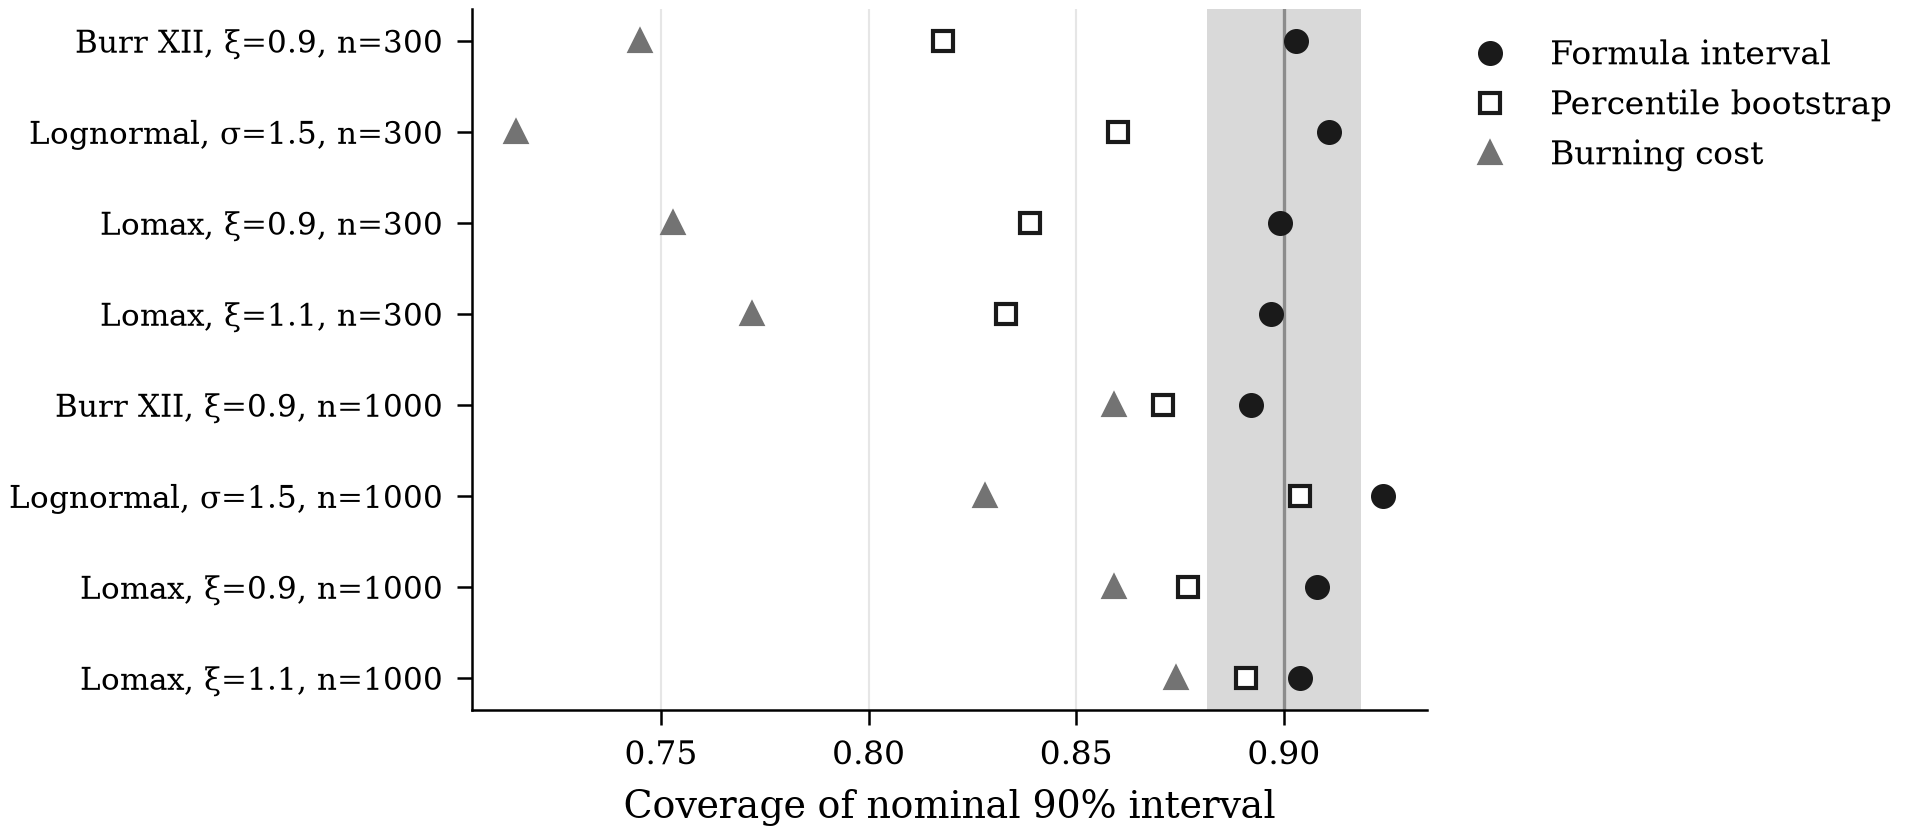

**fig_gpd_vs_bc_sim.png**

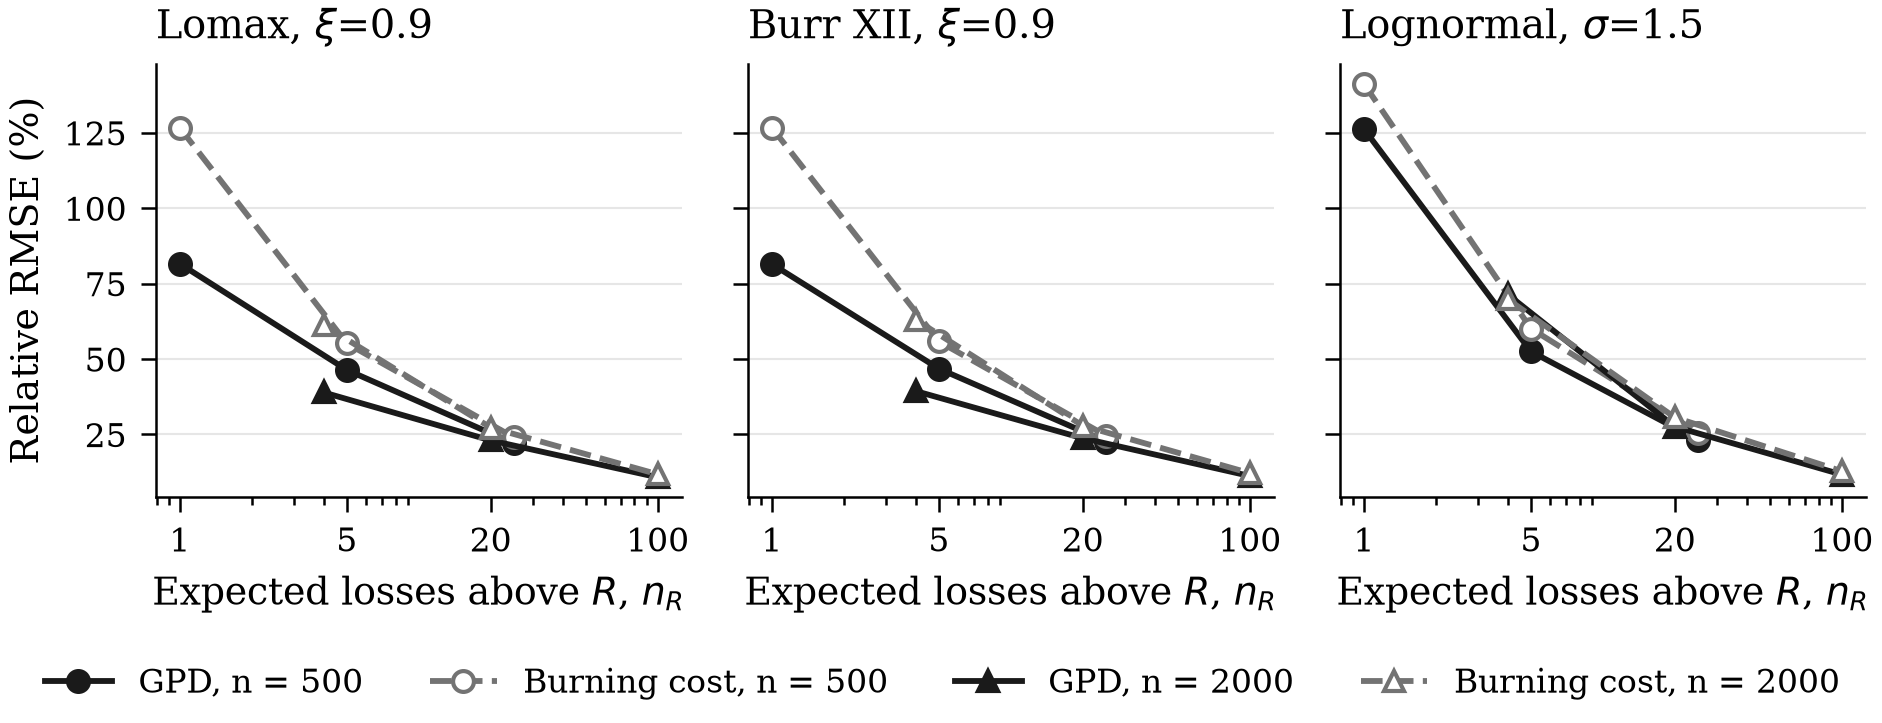

**fig_kappa.png**

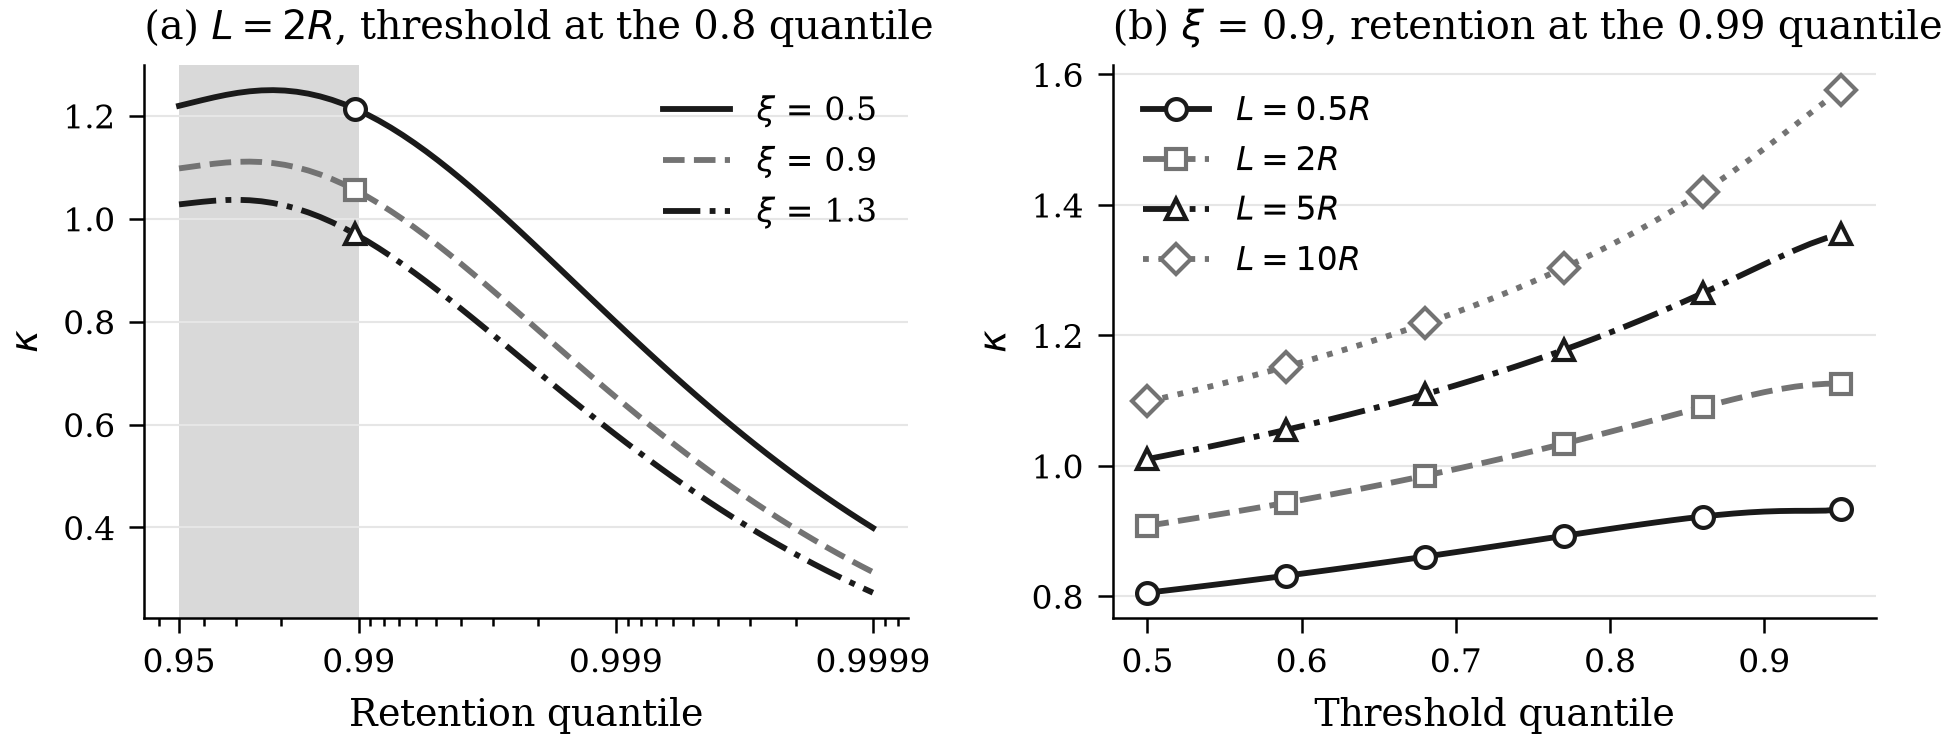

**fig_kappa_body.png**

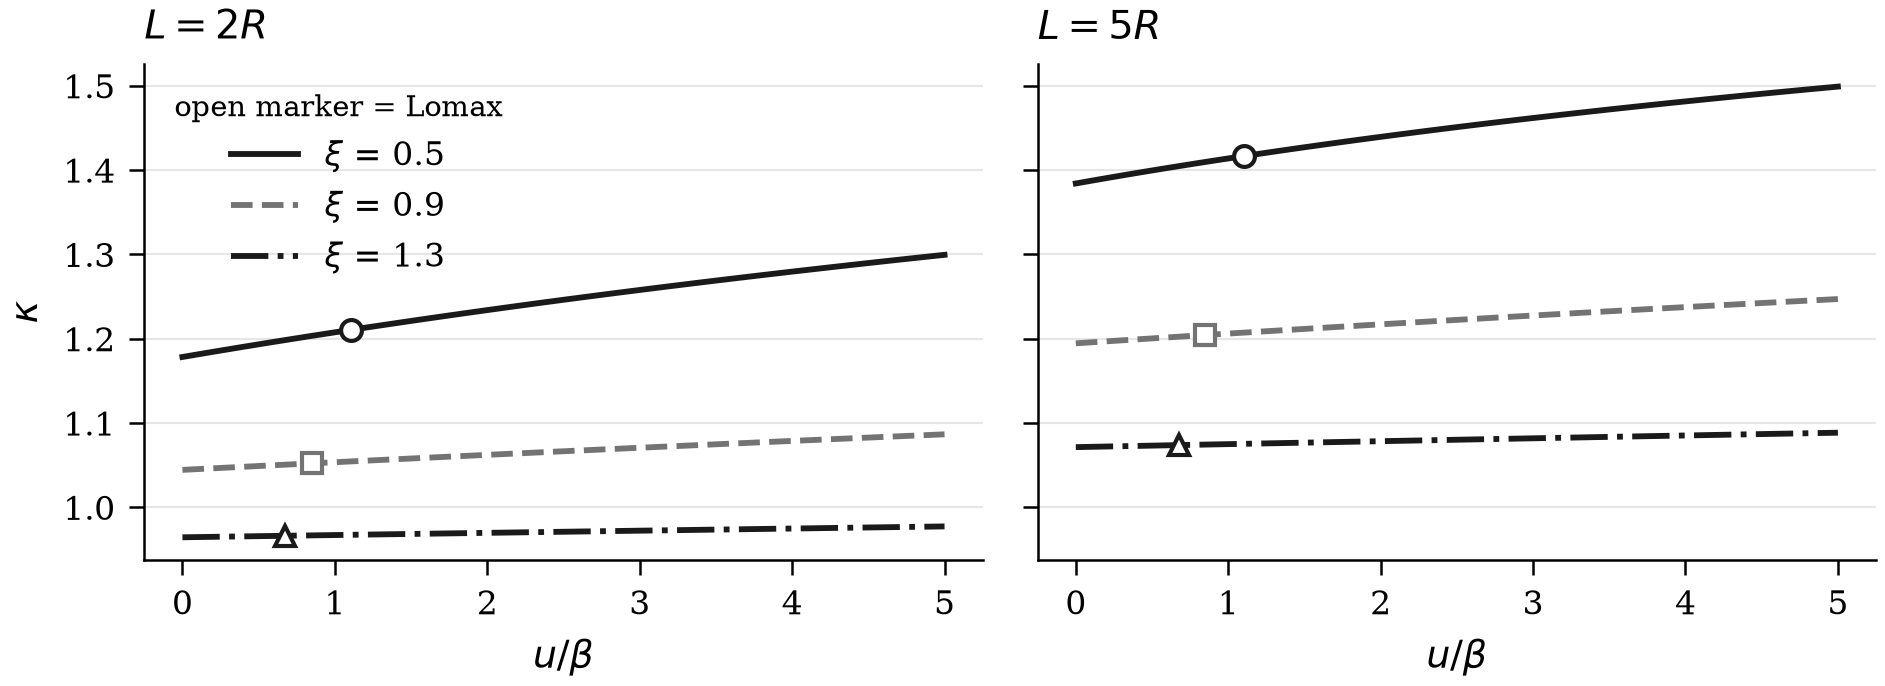

**fig_real_data.png**

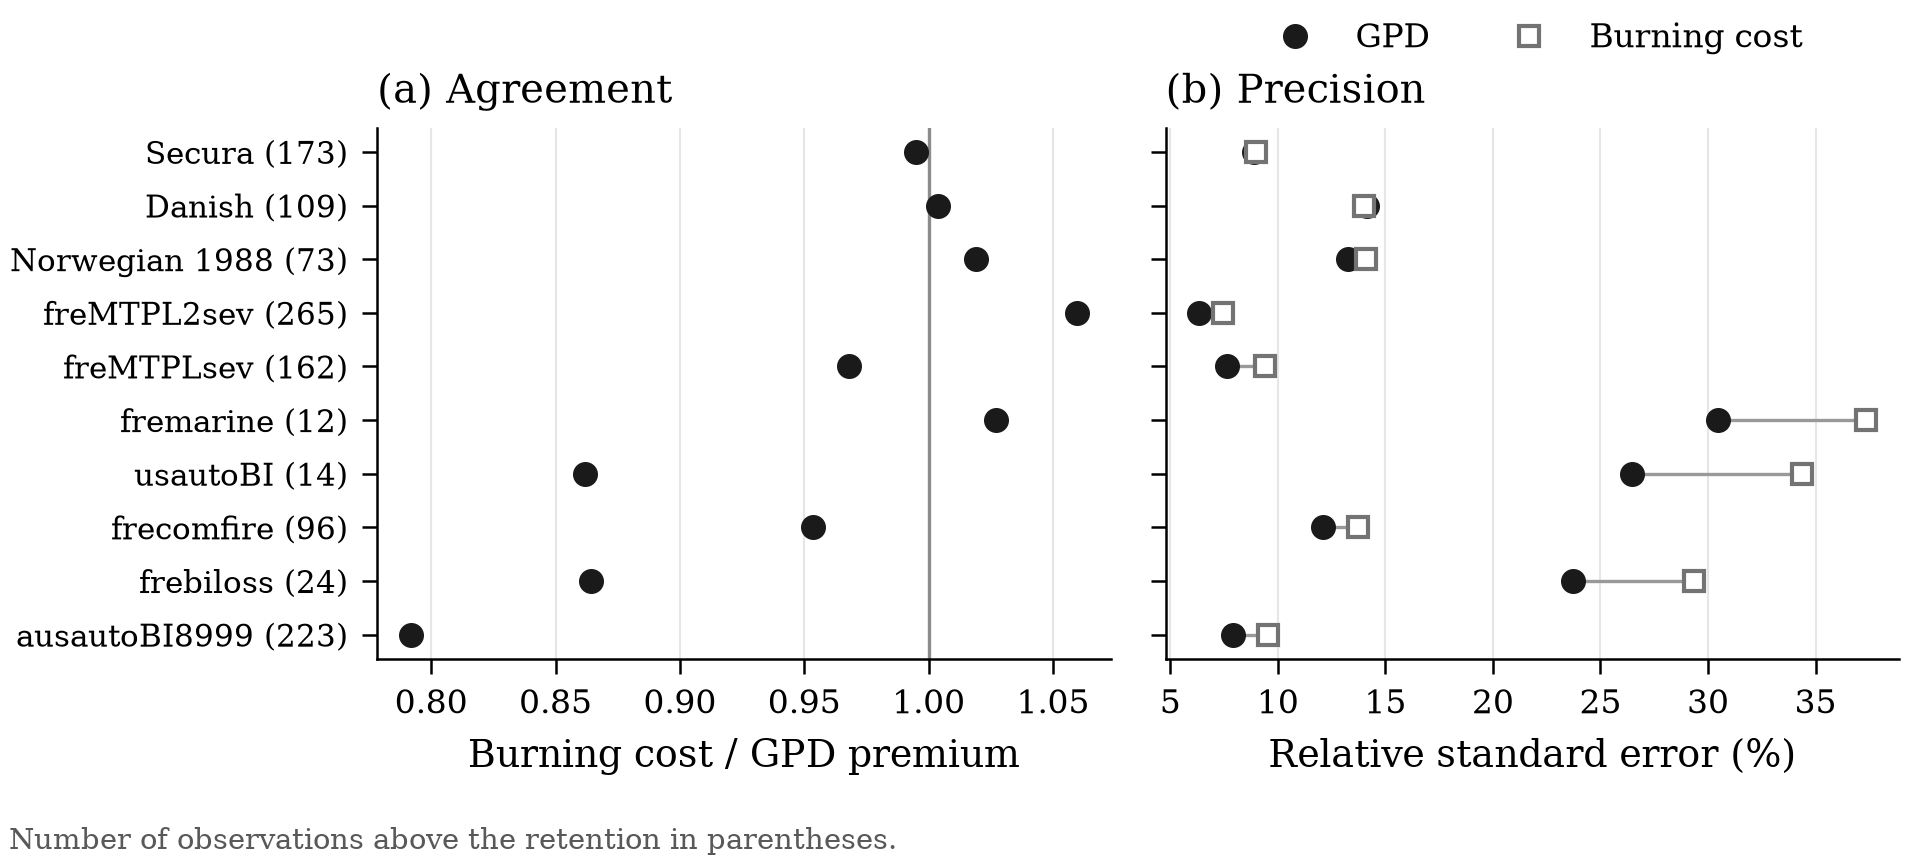

**fig_subsampling.png**

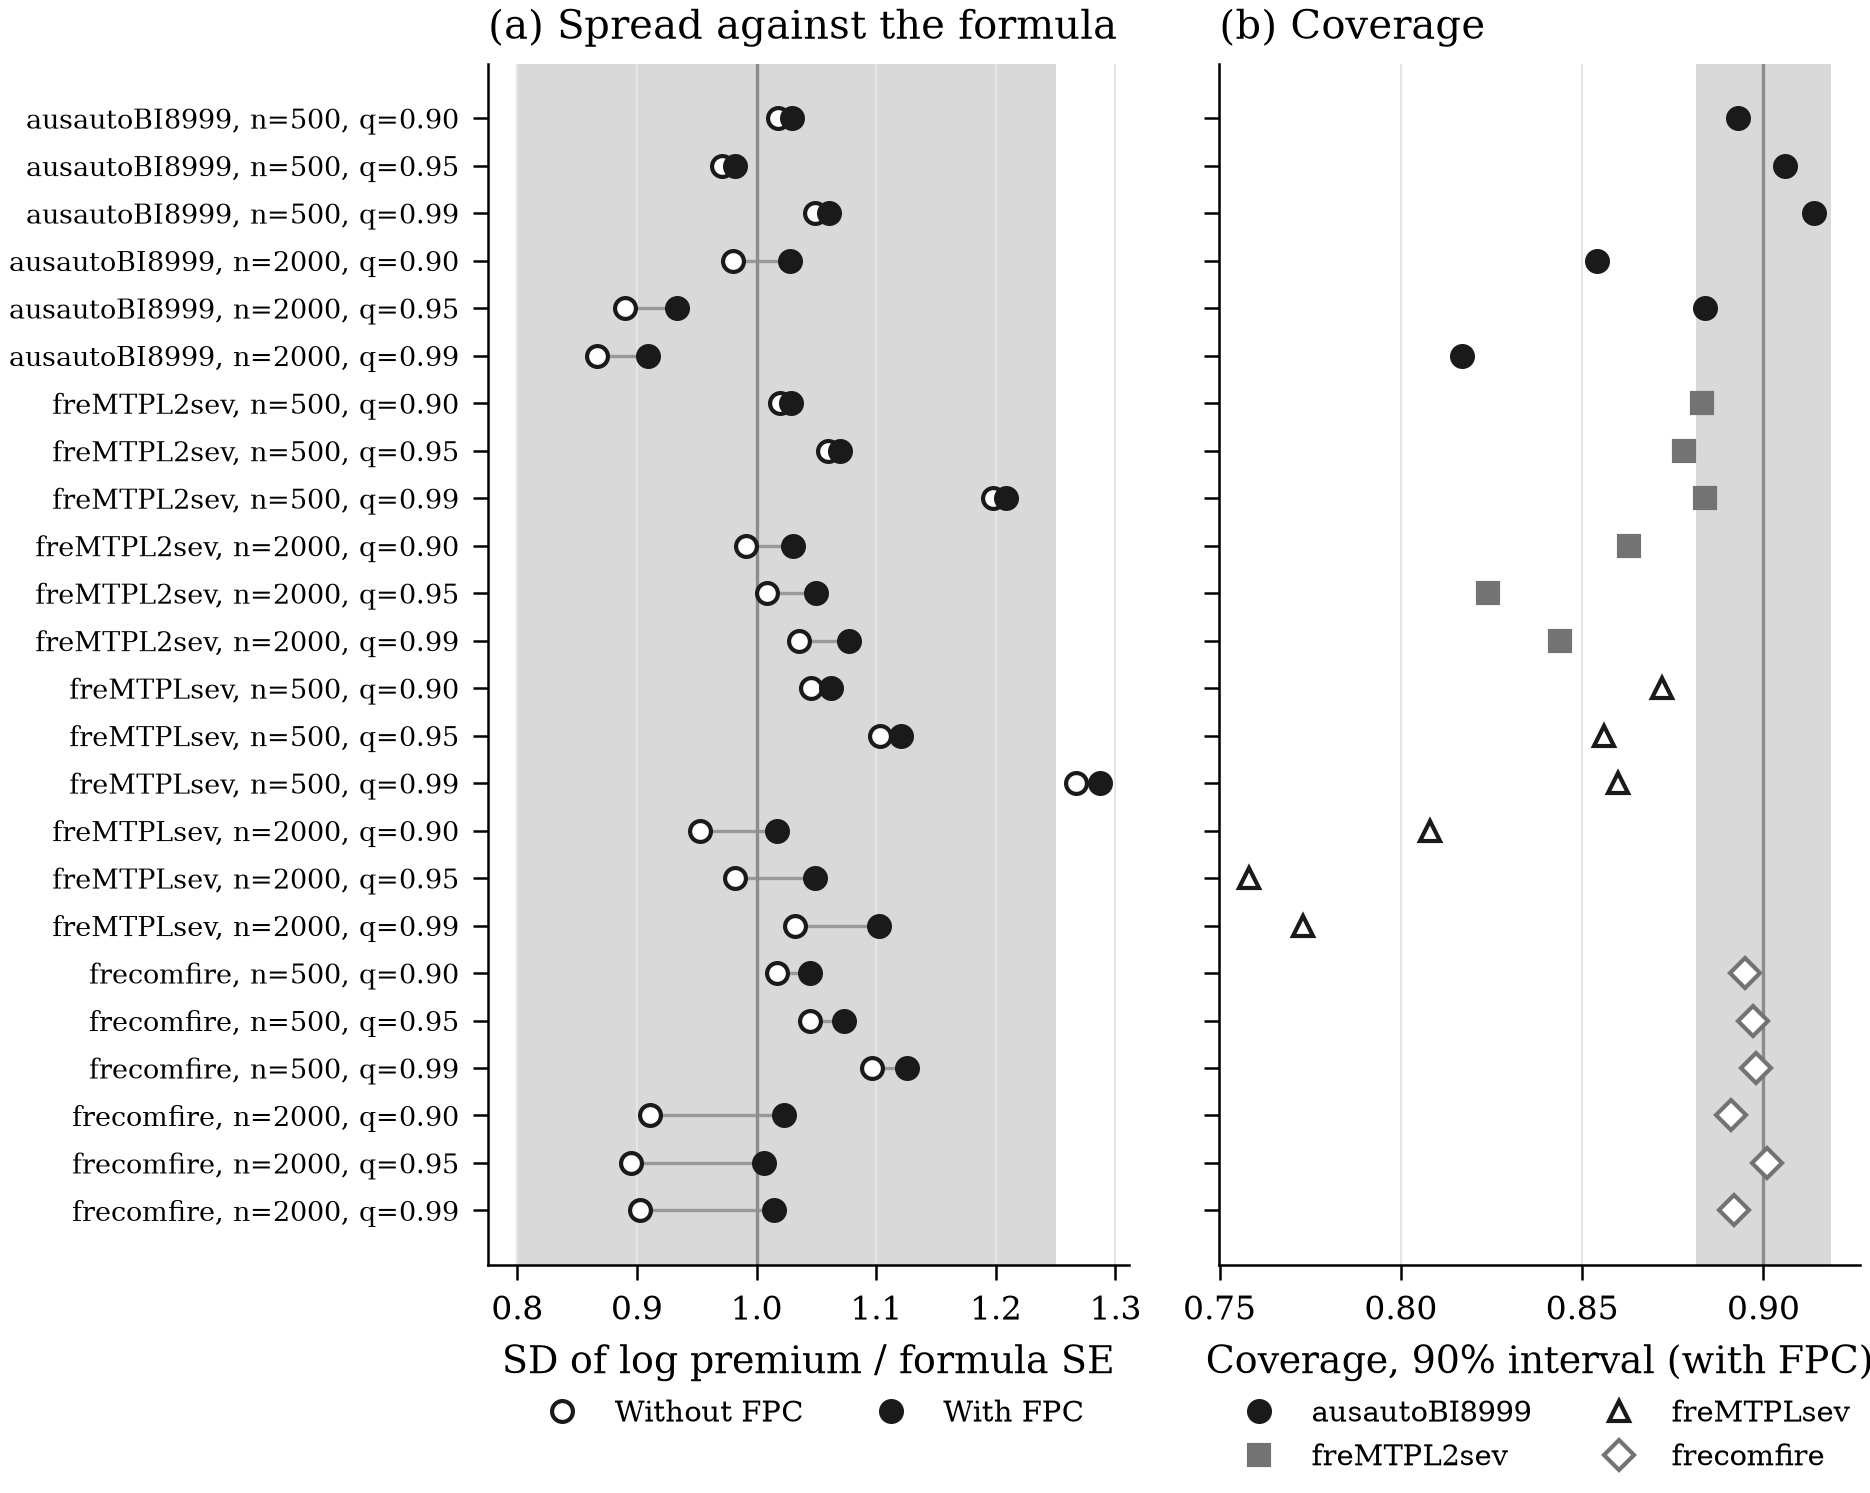

In [8]:
import os
from IPython.display import Image, display, Markdown

png_dir = r"C:\Users\admin\xol_figures\png"

for name in sorted(os.listdir(png_dir)):
    if name.endswith(".png"):
        display(Markdown("**" + name + "**"))
        display(Image(filename=os.path.join(png_dir, name), width=800))

In [9]:
# =============================================================================
# COLOUR FIGURES: makes xol_finish_colour.py from xol_finish.py (the black-and-
# white version stays as it is), then runs it as a separate program.
# Result: C:\Users\admin\xol_figures_colour.zip  (png, pdf, eps, tif)
# =============================================================================
import os, subprocess, sys

# Colour-blind-safe palette (Okabe-Ito): blue, vermillion, green, purple-pink
PAL = "['#0072B2', '#D55E00', '#009E73', '#CC79A7']"

src = open('xol_finish.py', encoding='utf8').read()
changes = [
    ("REPS_SUB=1000, REPS_BOOT=1000)", "REPS_SUB=1000, REPS_BOOT=1000, PAL=%s)" % PAL),
    ("col = INK if i != 1 else GRAY", "col = PAL[i]"),
    ("color=INK if i % 2 == 0 else GRAY", "color=PAL[i]"),
    ("color=INK, ls='-', marker=mk", "color=PAL[0], ls='-', marker=mk"),
    ("color=GRAY, ls='--', marker=mk", "color=PAL[1], ls='--', marker=mk"),
    ("'o', color=INK, markerfacecolor='white', markeredgewidth=1, label='Without FPC'",
     "'o', color=PAL[1], markerfacecolor='white', markeredgewidth=1, label='Without FPC'"),
    ("'o', color=INK, label='With FPC'", "'o', color=PAL[0], label='With FPC'"),
    ("'o', color=INK, label='Formula interval'", "'o', color=PAL[0], label='Formula interval'"),
    ("'s', color=INK, markerfacecolor='white', markeredgewidth=1, label='Percentile bootstrap'",
     "'s', color=PAL[1], markerfacecolor='white', markeredgewidth=1, label='Percentile bootstrap'"),
    ("'^', color=GRAY, label='Burning cost'", "'^', color=PAL[2], label='Burning cost'"),
    ("a.plot(t.bc_over_gpd, y, 'o', color=INK)", "a.plot(t.bc_over_gpd, y, 'o', color=PAL[0])"),
    ("'o', color=INK, label='GPD'", "'o', color=PAL[0], label='GPD'"),
    ("'s', color=GRAY, markerfacecolor='white', markeredgewidth=1, label='Burning cost'",
     "'s', color=PAL[1], markerfacecolor='white', markeredgewidth=1, label='Burning cost'"),
    ("os.path.join(HERE, 'xol_figures')", "os.path.join(HERE, 'xol_figures_colour')"),
    ("os.path.join(HERE, 'xol_figures.zip')", "os.path.join(HERE, 'xol_figures_colour.zip')"),
    ("DELETE_CHECKPOINTS = True", "DELETE_CHECKPOINTS = False"),
    ("(black-and-white safe)", "(colour version)"),
]
for old, new in changes:
    if old not in src:
        raise SystemExit('Could not find this text in xol_finish.py: ' + old)
    src = src.replace(old, new)

with open('xol_finish_colour.py', 'w', encoding='utf8') as f:
    f.write(src)
print('xol_finish_colour.py written - now drawing the colour figures...\n', flush=True)

r = subprocess.run([sys.executable, 'xol_finish_colour.py'], capture_output=True, text=True,
                   encoding='utf8', errors='replace')
print('\n'.join(l for l in r.stdout.splitlines() if not l.startswith('    fig_')))
if r.returncode != 0:
    print(r.stderr[-3000:])

xol_finish_colour.py written - now drawing the colour figures...

STEP 1  Figures (each in its own process), tables from C:\Users\admin\xol_out
  drawing fig_kappa
  !!! fig_kappa FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_kappa_body
  !!! fig_kappa_body FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_gpd_vs_bc_sim
  !!! fig_gpd_vs_bc_sim FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_subsampling
  !!! fig_subsampling FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_bootstrap
  !!! fig_bootstrap FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

  drawing fig_real_data
  !!! fig_real_data FAILED (exit code 3221226505: a compiled library aborted (0xC0000409))

Done: 25 files zipped into C:\Users\admin\xol_figures_colour.zip

STEP 2  Tables
Done: 14 files zipped into C:\Users\admin\xol_tables.zip

STEP 3  Checkpo

**fig_bootstrap_coverage.png**

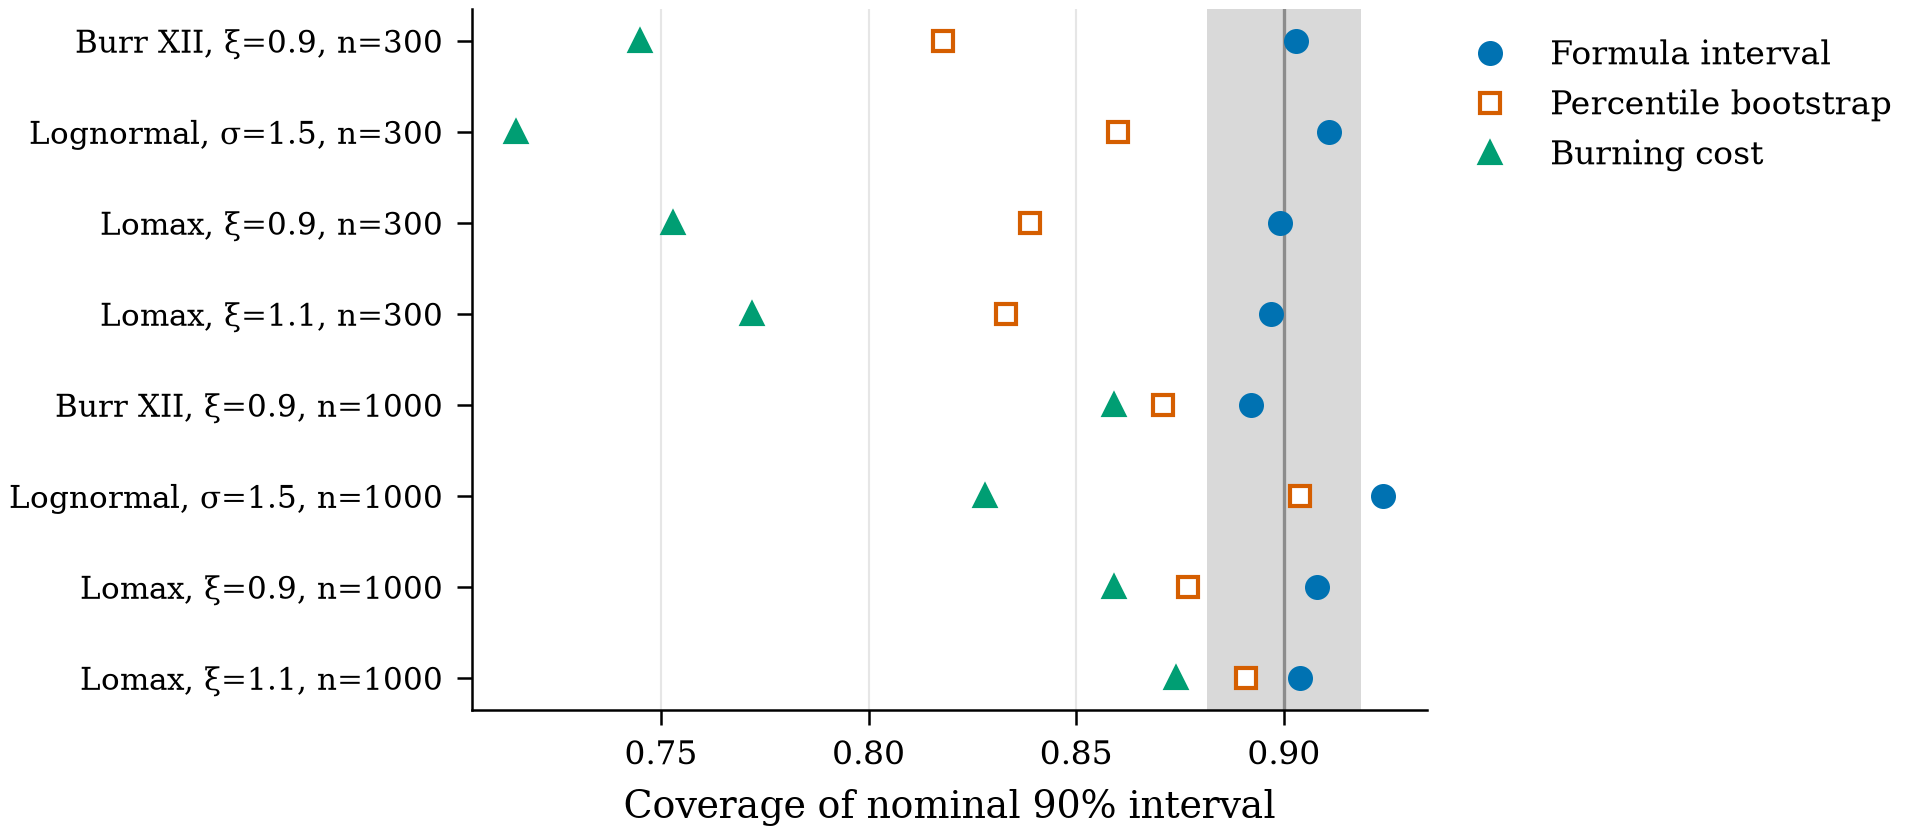

**fig_gpd_vs_bc_sim.png**

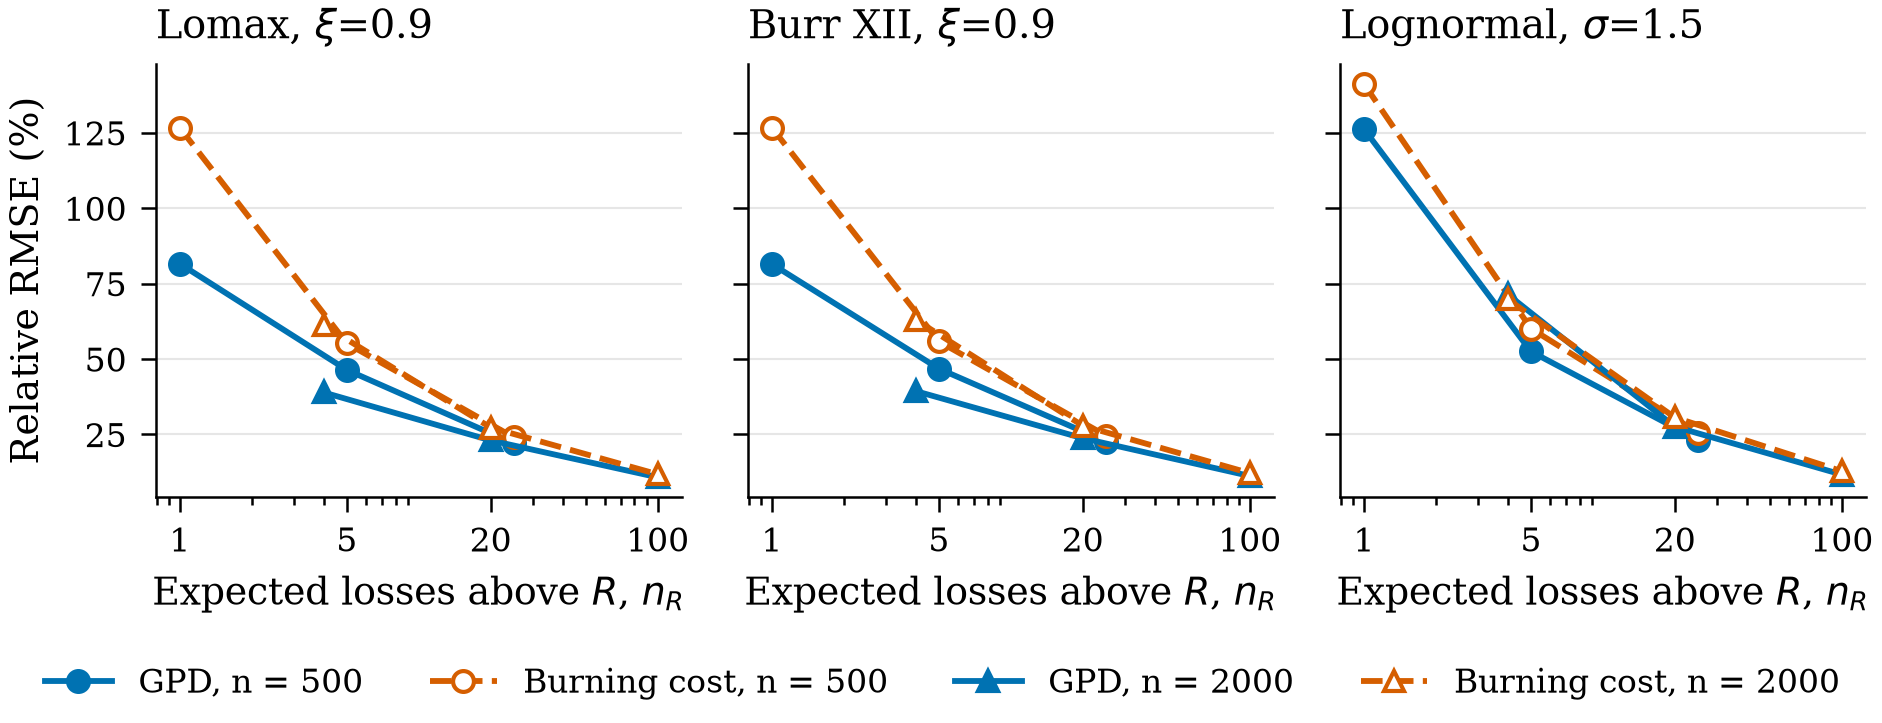

**fig_kappa.png**

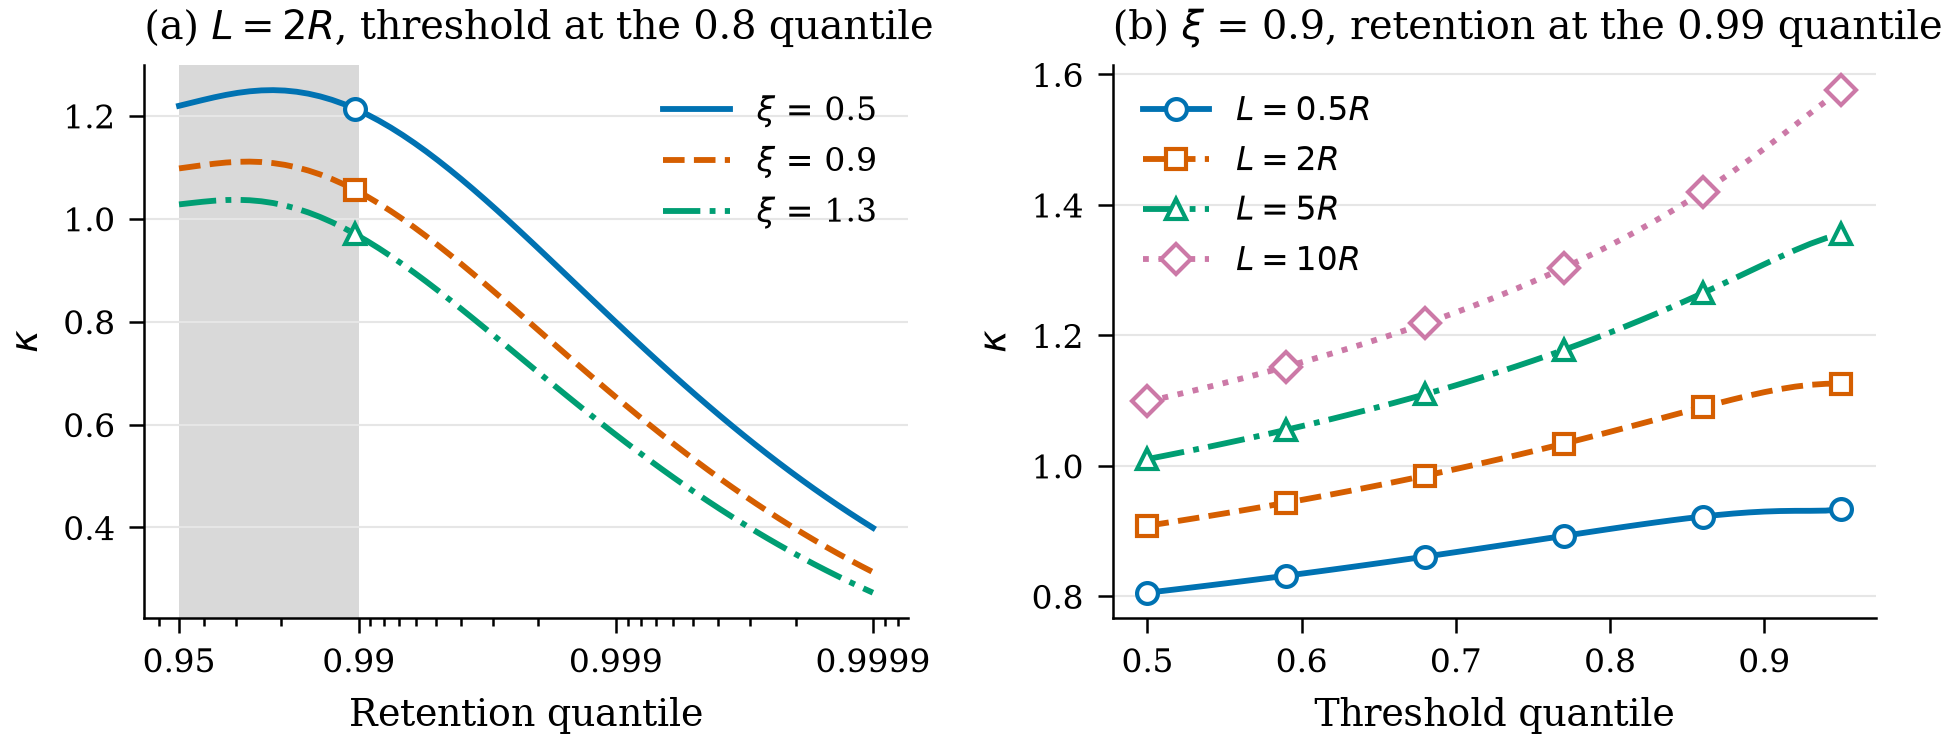

**fig_kappa_body.png**

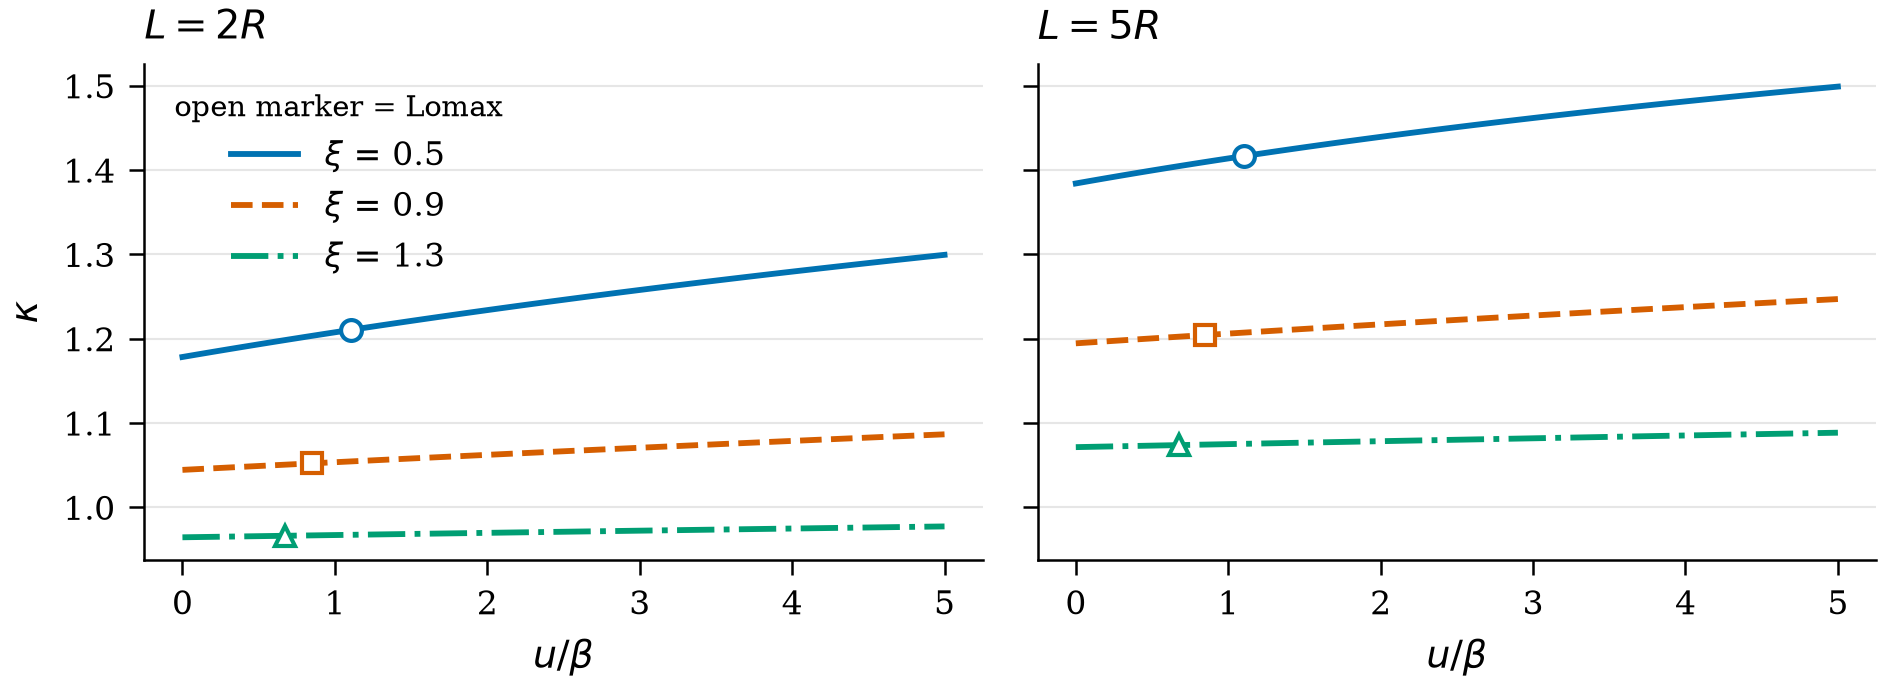

**fig_real_data.png**

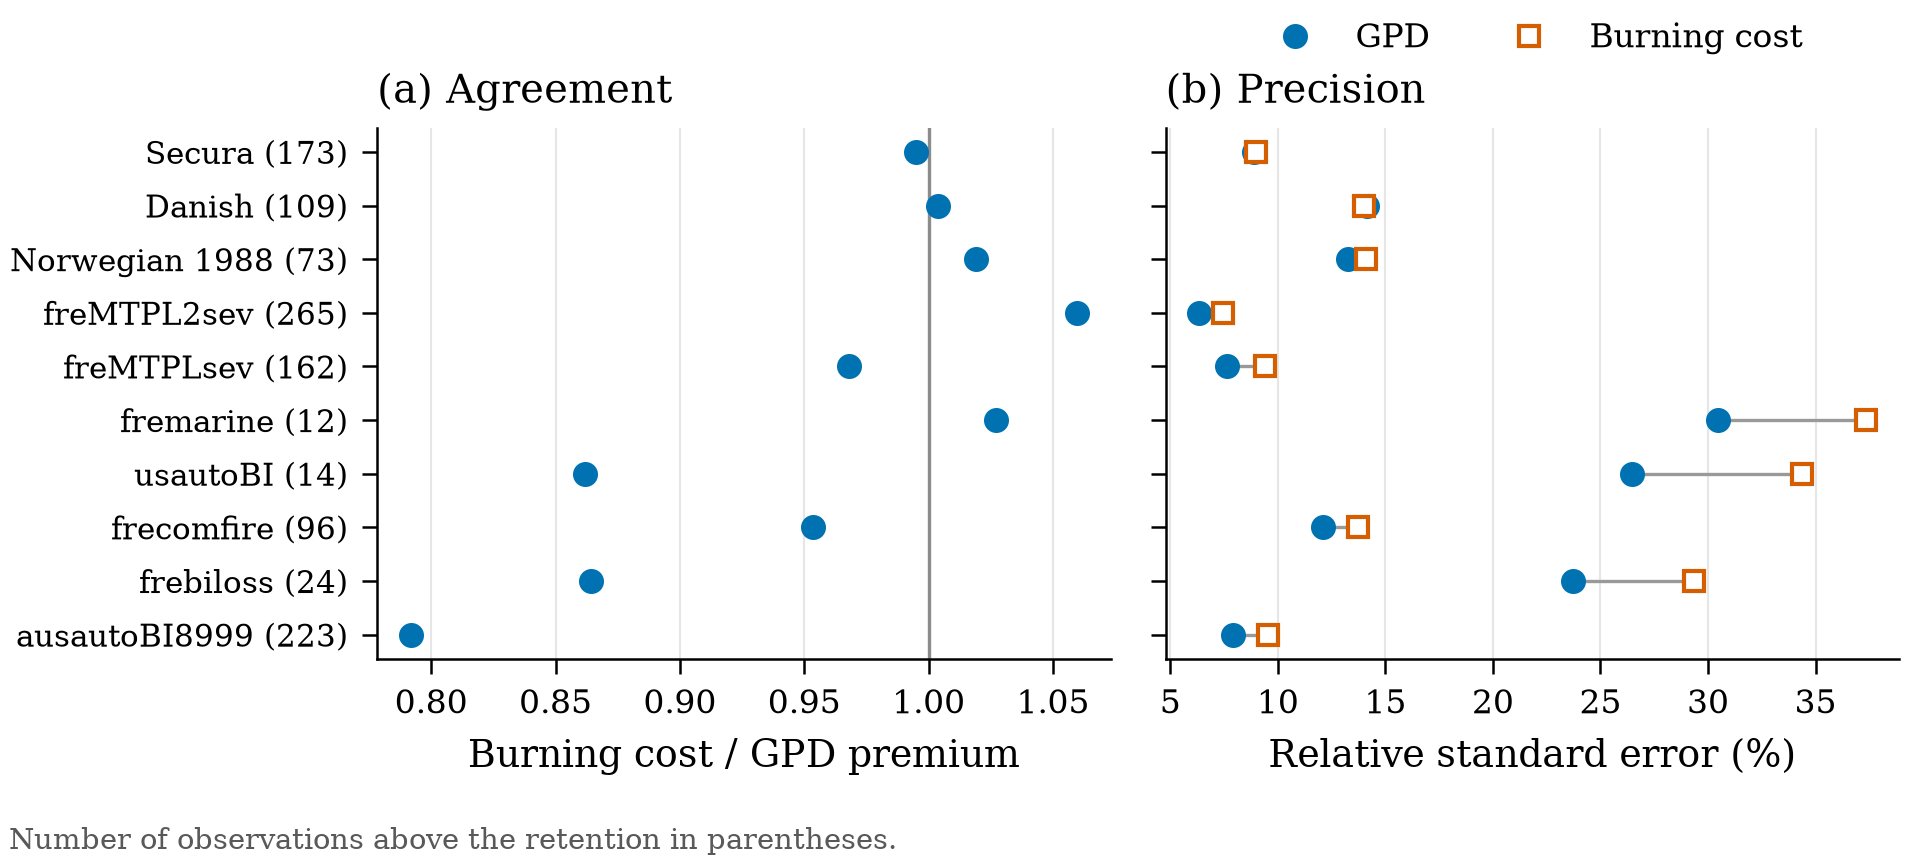

**fig_subsampling.png**

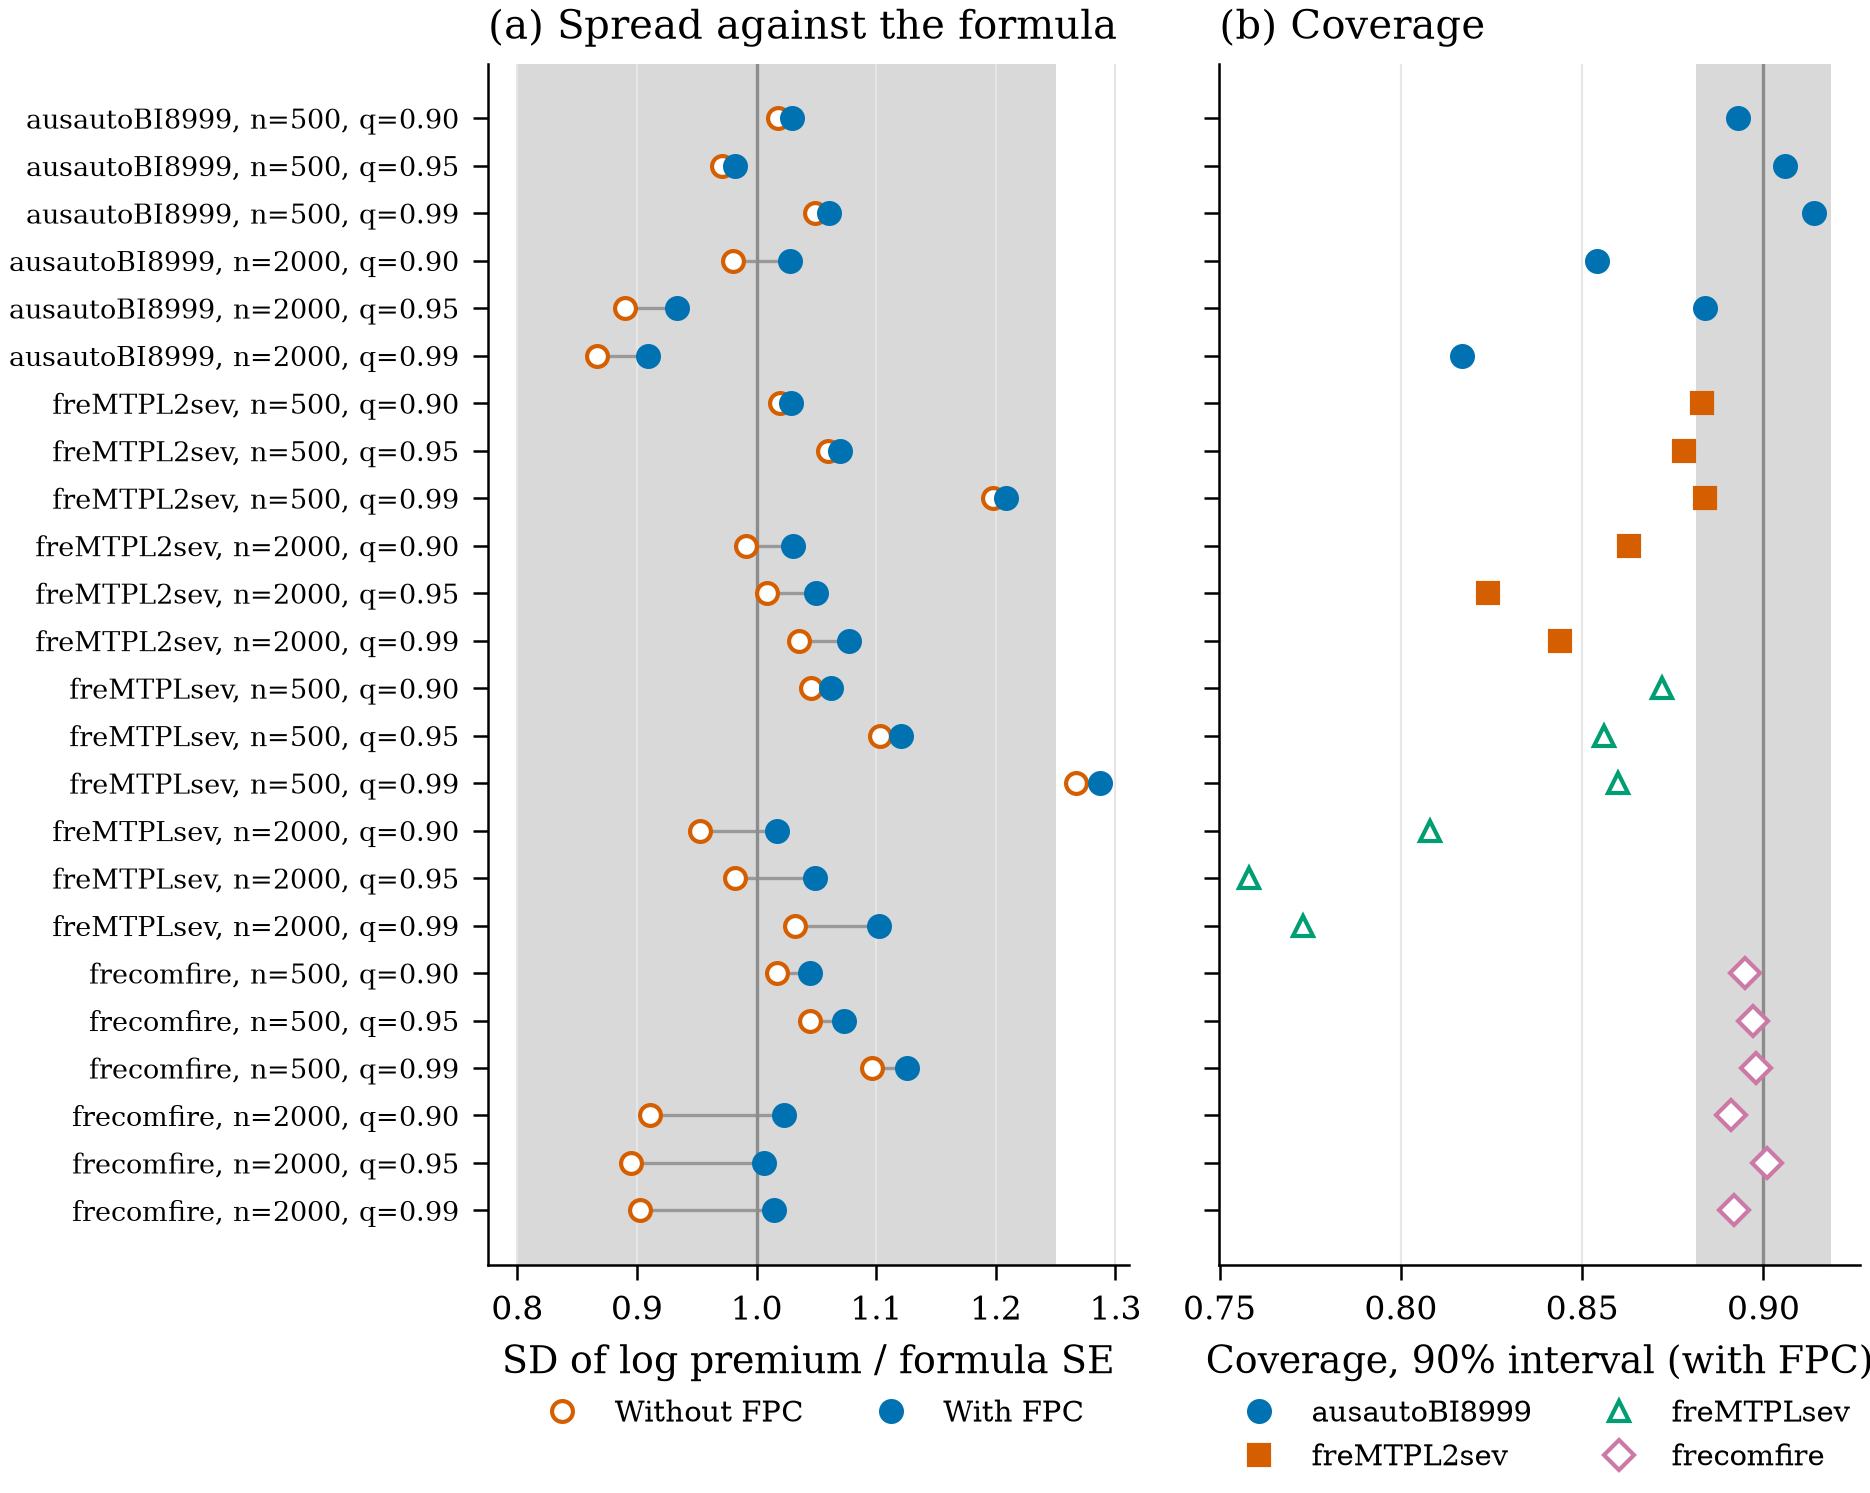

In [10]:
import os
from IPython.display import Image, display, Markdown

png_dir = r"C:\Users\admin\xol_figures_colour\png"
for name in sorted(os.listdir(png_dir)):
    if name.endswith(".png"):
        display(Markdown("**" + name + "**"))
        display(Image(filename=os.path.join(png_dir, name), width=800))